In [1]:
# ============================================================================
# CLOUD PREP CELL v2 — Kaggle plumbing only. NOT part of the pipeline.
# Every v2 cell below is UNTOUCHED verbatim. This cell exists only so the
# untouched code finds the dataset at its first-choice path
# (CANDIDATE_DATA_DIRS[0] = <cwd>/Brain_tumor_MRI_Dataset) and so that a
# previous run's results can be RESTORED instead of recomputed.
#   1. installs the extra packages Stages 8-9 need (quiet, idempotent —
#      the cloud base image lacks grad-cam; the V6 run died exactly here:
#      ModuleNotFoundError 'pytorch_grad_cam')
#   2. restores results/ from an attached previous-run output (kernel
#      source), so every completed stage — including ALL five trainings —
#      is skipped and only the remaining stages execute
#   3. links the attached MRI dataset to the path the v2 code expects
# ============================================================================
%pip install -q grad-cam onnx onnxruntime

import os, glob, shutil, json

INPUT_ROOT = os.environ.get('BT_MRI_INPUT_ROOT', '/kaggle/input')

def _manifest_stages(path):
    try:
        with open(path, encoding='utf-8') as fh:
            return set(json.load(fh)['stages'])
    except Exception:
        return set()

# ---- restore previous results (if a previous run's output is attached) ----
prev_results = None
for p in sorted(glob.glob(INPUT_ROOT + '/**/results/manifest.json', recursive=True)):
    prev_results = os.path.dirname(p)
    break
local_manifest = os.path.join(os.getcwd(), 'results', 'manifest.json')
if prev_results is None:
    print('No previous-run results input found — fresh run from Stage 0.')
elif _manifest_stages(local_manifest) >= _manifest_stages(os.path.join(prev_results, 'manifest.json')):
    print('Local results already complete — no restore needed '
          '(%d stages on disk).' % len(_manifest_stages(local_manifest)))
else:
    shutil.copytree(prev_results, os.path.join(os.getcwd(), 'results'), dirs_exist_ok=True)
    print('RESTORED previous results (%d stages complete) -> %s'
          % (len(_manifest_stages(local_manifest)), os.path.join(os.getcwd(), 'results')))

# ---- link the dataset ------------------------------------------------------
cands = sorted(set(glob.glob(INPUT_ROOT + '/**/*', recursive=True)))
src = next((p for p in cands
            if os.path.isdir(p) and os.path.isdir(os.path.join(p, 'Training'))), None)
assert src, 'No %s folder contains Training/ — attached inputs: %s' % (INPUT_ROOT, cands)
link = os.path.join(os.getcwd(), 'Brain_tumor_MRI_Dataset')
if not os.path.exists(link):
    try:
        os.symlink(src, link)
    except OSError:
        # Windows without symlink privilege: fall back to a directory junction
        os.system('cmd /c mklink /J "%s" "%s"' % (link, src))
        assert os.path.isdir(link), 'could not link dataset at %s' % link
print('Dataset linked:', link, '->', src)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 1.3 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.6/23.6 MB 75.1 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.
No previous-run results input found — fresh run from Stage 0.
Dataset linked: /kaggle/working/Brain_tumor_MRI_Dataset -> /kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset


# Brain Tumor MRI Classification — v2 Clean Rebuild (v8, Kaggle T4 edition)

**Student:** Rishab Arya · M.Tech CSE (Data Science), Bennett University · Enrollment S24MTCG0018
**Lineage:** clean rebuild of the CSET 605 research-practices project (canonical run: Azure ML CPU session, Nov 2025). This v8 edition is the cloud-GPU cut: one Tesla T4 does everything, top to bottom.

**Target:** a Kaggle notebook session with a Tesla T4. Six models train on CUDA (a ~90k-parameter baseline plus five lightweight architectures, ~1.7 h total). Deployment work is deliberately lean — ONNX export + parity (Stage 9) and a CUDA-only inference-speed check (Stage 10). No OpenVINO / INT8 / multi-device matrix: the v7 run already measured that story on CPU and iGPU devices and recorded the honest (negative) results, which live in its `results/` artifacts.

**The headline is not accuracy — it is the audit.** Stage 2 quantifies this benchmark's leakage (most test images share a perceptual hash with training images), Stage 11 re-scores every model on the leak-free subset, and Stage 12 reports the best model as mean ± std across three seeds. The full-vs-clean gap is the project's central finding.

## Design principle — stage-gated, idempotent, resumable

> Every stage writes its artifacts to disk, then marks itself complete in `results/manifest.json`. Re-running any cell **skips work whose artifacts already exist**. Training keeps a resumable `training_state.pt`, so an interrupted training **resumes** at the next epoch instead of restarting. Nothing — not one epoch — is ever computed twice.

## What v2 fixes vs the original (top items — full list in README.md)

| Original (Nov 2025 runs) | v2 |
|---|---|
| "Azure GPU run" was actually a **CPU run** (device: cpu, batch 8, F4sv2 compute) — presented as cloud-GPU training | Honest training on a real GPU, hardware limits documented |
| sklearn broken in that session → **all metrics were homemade fallback approximations**; `roc_auc_score` literally returned 0.5 | Real scikit-learn metrics; environment recorded in `environment.json` |
| Results appended across sessions → **6-row CSV for 5 models** (duplicate MobileViT-S) | Comparison table rebuilt fresh from one JSON per model — duplicates impossible |
| 3 incompatible result schemas; Automated Analysis crashed (`KeyError: 'f1_score'`) | One unified schema; analysis completes by construction |
| ONNX export cell crashed (`ModuleNotFoundError`) — the shipped .onnx was the local run's file | Export + onnxruntime **parity verification** before trusting the artifact |
| "INT8 quantization" was a no-op (0.99× compression, file got *bigger*) | v7 ran NNCF static PTQ with a full-test ΔF1 ≤ 1% gate — it **failed the gate honestly**; v8 drops the stage for the GPU-only edition rather than shipping a negative artifact |
| Grad-CAM: deprecated hooks, applied to `all_results[0]` (not the best model), unseeded samples | `pytorch-grad-cam` library, actual best model, ViT reshape-transform, seeded samples — correct AND misclassified cases, with the true→pred confusion profile |
| Timing benchmark: GPU batch 8 vs CPU batch 4, 0.0 written as a "measurement" | One protocol; median of 100/30 iters; warmup; CUDA-synchronized; 0.0 never reported |
| GaussNoise `var_limit=(10,50)` **silently ignored** by albumentations 2.x (default noise used instead) | `std_range=(0.04, 0.2)` — restores the intended noise level |
| Dataset cited as `sartajbhuvaji/...` but is actually `masoudnickparvar/brain-tumor-mri-dataset` | Provenance corrected + dataset-version history; exact/near-duplicate audit quantifies the dataset's known leakage risk |
| 92–96 MB pickle caches holding live model objects — restore always failed in a fresh kernel | Plain JSON + bare state_dicts, atomic writes |
| No baseline; single seed; single split | 90k-param BaselineCNN first; best model × 3 seeds (mean ± std); dual metrics on full vs leak-free test set |

## Stage map

| Stage | What it does | Skips if present |
|---|---|---|
| 0 | imports · device · config · stage-gate system | — (pure setup) |
| 1 | environment record + dataset integrity | `results/environment.json` |
| 2 | data-quality audit (exact + near duplicates) | `results/data_quality.json` |
| 3 | seeded split · transforms · dataset · loaders | `results/split.json` |
| 4 | EDA plots | `results/plots/*.png` |
| 5 | training infrastructure · BaselineCNN · model factory | — |
| 6a–6f | **one model at a time** (baseline + five architectures) — train, evaluate once, save | `results/models/<name>/eval.json` |
| 7 | comparison table (rebuilt from JSONs) | — (derived, cheap) |
| 8 | explainability (Grad-CAM, best model, correct + failure cases) | manifest |
| 9 | ONNX export + parity verification | manifest |
| 10 | inference speed on the T4 (PyTorch CUDA) | `results/benchmarks.csv` |
| 11 | clean-subset evaluation (full vs leak-free dual metrics) | `results/clean_subset_report.json` |
| 12 | seed stability — best model × 3 seeds (mean ± std) | `results/seed_stability.json` |
| 13 | final summary (results/SUMMARY.md) | manifest |

**How to run:** attach the `masoudnickparvar/brain-tumor-mri-dataset` input, enable the GPU, and **Save & Run All**. The prep cell installs `grad-cam`/`onnx`/`onnxruntime`, restores any attached previous-run results (so a re-run continues instead of retraining), and links the dataset to the path the notebook expects.

## Stage 0 — imports, device, config, stage-gate system

In [2]:
# ============================================================================
# STAGE 0 · IMPORTS & VERSION CHECK
# No package installs happen inside this notebook — the environment is
# prebuilt (see README.md). This fixes the original's %pip-install-then-
# forgot-to-restart-kernel crash. If any import below fails, the notebook
# fails LOUDLY at the top instead of silently switching to fallback code.
# ============================================================================
import sys, os, json, time, gc, math, random, shutil, hashlib, warnings
from pathlib import Path
from datetime import datetime

import numpy as np
if "ipykernel" not in sys.modules:
    import matplotlib
    matplotlib.use("Agg")
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

import cv2
import albumentations as A
from albumentations.pytorch import ToTensorV2

import timm
import sklearn
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_curve, auc)
from sklearn.preprocessing import label_binarize
import pandas as pd

try:
    from IPython.display import display
except Exception:
    display = print

warnings.filterwarnings("ignore")

def now():
    return datetime.now().strftime("%H:%M:%S")

VERSIONS = {
    "python": sys.version.split()[0],
    "torch": torch.__version__,
    "timm": timm.__version__,
    "albumentations": A.__version__,
    "opencv": cv2.__version__,
    "sklearn": sklearn.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
}
print(" | ".join(f"{k} {v}" for k, v in VERSIONS.items()))

python 3.12.13 | torch 2.10.0+cu128 | timm 1.0.26 | albumentations 2.0.8 | opencv 4.13.0 | sklearn 1.6.1 | numpy 2.0.2 | pandas 2.3.3


In [3]:
# ============================================================================
# STAGE 0 · DEVICE RESOLUTION & SEEDS
# Hardware target: a Kaggle notebook session with a Tesla T4 GPU. Training
# and the Stage-10 speed check run on CUDA. There is deliberately no
# OpenVINO / INT8 / CPU-vs-GPU machinery in this edition — the v7 results
# already recorded that story for CPU and iGPU devices.
# ============================================================================
def pick_device():
    if hasattr(torch, "xpu") and torch.xpu.is_available():
        return torch.device("xpu"), "Intel GPU (XPU)"
    if torch.cuda.is_available():
        return torch.device("cuda"), "CUDA GPU"
    return torch.device("cpu"), "CPU"

DEVICE, DEVICE_NAME = pick_device()
torch.set_num_threads(4)   # CPU-side ops / data loading

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
set_seed()

print(f"Training device: {DEVICE} ({DEVICE_NAME}) | torch threads: {torch.get_num_threads()}")

Training device: cuda (CUDA GPU) | torch threads: 4


In [4]:
# ============================================================================
# STAGE 0 · CONFIGURATION — single source of truth
# The training recipe is IDENTICAL to the reference run (AdamW 1e-4/1e-4,
# cosine schedule, 30 epochs, early stop on val macro-F1, patience 7) so the
# v2 numbers stay comparable with the original report.
# Documented deviations from the reference (each fixes a verified flaw):
#   · batch 16 (reference CPU session used 8; local GPU session used 16)
#   · class balancing via sampler ONLY (reference double-balanced:
#     WeightedRandomSampler + weighted CrossEntropyLoss)
#   · GaussNoise via std_range (albumentations 2.x silently IGNORED the
#     original's var_limit argument)
#   · real sklearn metrics (the reference session silently ran with broken
#     sklearn and homemade fallback metric code)
# ============================================================================
class Config:
    # ---- paths --------------------------------------------------------
    BASE_DIR = Path.cwd()   # run Jupyter from this project folder
    CANDIDATE_DATA_DIRS = [
        BASE_DIR / "Brain_tumor_MRI_Dataset",
        Path(r" <redacted>"),
        Path(r" <redacted>"),
        Path(r" <redacted>"),
    ]
    RESULTS_DIR  = BASE_DIR / "results"
    MODELS_DIR   = RESULTS_DIR / "models"
    PLOTS_DIR    = RESULTS_DIR / "plots"
    EXPORT_DIR   = RESULTS_DIR / "exports"
    MANIFEST_PATH = RESULTS_DIR / "manifest.json"
    # ---- data (same as reference) --------------------------------------
    CLASS_NAMES = ["glioma", "meningioma", "notumor", "pituitary"]
    NUM_CLASSES = 4
    IMG_SIZE = 224
    VAL_SPLIT = 0.20          # carved from Kaggle 'Training' only, seed 42
    SEED = 42
    # Known-good dataset profiles. The public Kaggle version of
    # masoudnickparvar/brain-tumor-mri-dataset is balanced 5,600/1,600
    # (1,400/400 per class). The local v2 copy used for the original CPU
    # benchmark is unbalanced 5,712/1,311. Either profile is accepted by
    # the integrity check.
    KNOWN_COUNT_PROFILES = [
        {
            "train": {"glioma": 1321, "meningioma": 1339, "notumor": 1595, "pituitary": 1457},
            "test":  {"glioma": 300,  "meningioma": 306,  "notumor": 405,  "pituitary": 300},
        },
        {
            "train": {"glioma": 1400, "meningioma": 1400, "notumor": 1400, "pituitary": 1400},
            "test":  {"glioma": 400,  "meningioma": 400,  "notumor": 400,  "pituitary": 400},
        },
    ]
    # ---- training (reference recipe) ------------------------------------
    BATCH_SIZE = 16
    NUM_WORKERS = 2
    EPOCHS = 30
    LEARNING_RATE = 1e-4
    WEIGHT_DECAY = 1e-4
    SCHEDULER_T_MAX = 30
    EARLY_STOP_PATIENCE = 7
    EARLY_STOP_MIN_DELTA = 0.002
    GRAD_CLIP = 1.0
    # ---- the same five lightweight architectures ------------------------
    MODELS = {
        "EfficientNet-B0":   ("efficientnet_b0",       "CNN"),
        "MobileNetV3-Small": ("mobilenetv3_small_100", "CNN"),
        "MobileViT-S":       ("mobilevit_s",           "Hybrid ViT"),
        "DeiT-Tiny":         ("deit_tiny_patch16_224", "ViT"),
        "TinyViT-5M":        ("tiny_vit_5m_224",       "ViT"),
    }
    NORM_MEAN = [0.485, 0.456, 0.406]
    NORM_STD  = [0.229, 0.224, 0.225]
for d in (Config.RESULTS_DIR, Config.MODELS_DIR, Config.PLOTS_DIR, Config.EXPORT_DIR):
    d.mkdir(parents=True, exist_ok=True)
DATA_DIR = next((p for p in Config.CANDIDATE_DATA_DIRS if (p / "Training").is_dir()), None)
assert DATA_DIR is not None, (
    "Dataset not found. Place 'Brain_tumor_MRI_Dataset' next to this notebook or "
    "download masoudnickparvar/brain-tumor-mri-dataset (the dataset on disk IS this "
    "one — the original notebook's download cell cited sartajbhuvaji/..., a different "
    "dataset, incorrectly) and add its path to CANDIDATE_DATA_DIRS.")
TRAIN_RAW_DIR, TEST_DIR = DATA_DIR / "Training", DATA_DIR / "Testing"
if "Brain Tumor MRI Project v2" not in str(Config.BASE_DIR):
    print("NOTE: artifacts will be created under", Config.BASE_DIR,
          "- make sure Jupyter's working directory is the project folder.")
print("Project dir :", Config.BASE_DIR)
print("Dataset     :", DATA_DIR)


NOTE: artifacts will be created under /kaggle/working - make sure Jupyter's working directory is the project folder.
Project dir : /kaggle/working
Dataset     : /kaggle/working/Brain_tumor_MRI_Dataset


In [5]:
# ============================================================================
# STAGE 0 · STAGE-GATE SYSTEM
# "Everything happens one at a time, exactly once." Every stage writes its
# artifacts, and only THEN marks itself complete in results/manifest.json
# (written atomically: temp file + replace). Re-running any cell skips work
# whose artifacts already exist. Training additionally keeps a resumable
# training_state.pt, so even an interrupted TRAINING resumes mid-run instead
# of restarting. No pickle-of-live-objects anywhere — all artifacts are
# plain JSON / bare state_dicts (the original's 92-96 MB caches unpickled
# objects and its restore failed in every fresh kernel).
# ============================================================================
def _read_manifest():
    if Config.MANIFEST_PATH.exists():
        return json.loads(Config.MANIFEST_PATH.read_text(encoding="utf-8"))
    return {"stages": {}}

def atomic_write_json(path, obj):
    path = Path(path)
    tmp = path.with_suffix(path.suffix + ".tmp")
    tmp.write_text(json.dumps(obj, indent=2), encoding="utf-8")
    tmp.replace(path)

def atomic_save_state(obj, path):
    tmp = Path(path).with_suffix(Path(path).suffix + ".tmp")
    torch.save(obj, tmp)
    tmp.replace(path)

def stage_done(stage):
    return stage in _read_manifest()["stages"]

def mark_stage(stage, info=None):
    m = _read_manifest()
    m["stages"][stage] = {"completed_at": datetime.now().isoformat(timespec="seconds"),
                         "info": info or {}}
    atomic_write_json(Config.MANIFEST_PATH, m)
    print(f"  [stage complete] {stage}")

done = _read_manifest()["stages"]
print("Stages already complete:", ", ".join(sorted(done)) if done else "(none — fresh run)")

Stages already complete: (none — fresh run)


## Stage 1 — environment record + dataset integrity

In [6]:
# ============================================================================
# STAGE 1 · ENVIRONMENT RECORD + DATASET INTEGRITY
# Records what software/hardware produced the results and verifies the dataset
# has exactly the expected class counts before any compute is spent on it.
# ============================================================================
stage = "environment"
if stage_done(stage):
    print(f"SKIP {stage} — recorded in results/environment.json")
else:
    import platform
    env = {
        "recorded_at": datetime.now().isoformat(timespec="seconds"),
        "machine": platform.platform(),
        "processor": platform.processor(),
        "training_device": str(DEVICE),
        "device_name": DEVICE_NAME,
        "torch_threads": torch.get_num_threads(),
    }
    env.update({f"pkg_{k}": str(v) for k, v in VERSIONS.items()})
    counts = {}
    for split_dir, tag in ((TRAIN_RAW_DIR, "train"), (TEST_DIR, "test")):
        counts[tag] = {c: len(list((split_dir / c).glob("*.jpg"))) +
                         len(list((split_dir / c).glob("*.png")))
                      for c in Config.CLASS_NAMES}
    env["dataset_dir"] = str(DATA_DIR)
    env["dataset_counts"] = counts
    env["dataset_provenance"] = (
        "Kaggle 'Brain Tumor MRI Dataset' by Masoud Nickparvar "
        "(masoudnickparvar/brain-tumor-mri-dataset). "
        "Public Kaggle version: 5,600 Training / 1,600 Testing "
        "(balanced 1,400/class train, 400/class test). "
        "Local v2 copy: 5,712 Training / 1,311 Testing (unbalanced). "
        "Combines Figshare (Cheng Jun) + SARTAJ + Br35H. The original notebook's "
        "download cell cited sartajbhuvaji/brain-tumor-classification-mri, which is "
        "a DIFFERENT dataset (2,870/3,919) - citation corrected in v2.")
    atomic_write_json(Config.RESULTS_DIR / "environment.json", env)
    ok = any(counts == profile for profile in Config.KNOWN_COUNT_PROFILES)
    print("Dataset counts :", json.dumps(counts))
    print("Known profiles :", json.dumps(Config.KNOWN_COUNT_PROFILES))
    print("Integrity check:", "PASS" if ok else "MISMATCH — investigate before training!")
    mark_stage(stage, {"integrity_ok": ok})


Dataset counts : {"train": {"glioma": 1400, "meningioma": 1400, "notumor": 1400, "pituitary": 1400}, "test": {"glioma": 400, "meningioma": 400, "notumor": 400, "pituitary": 400}}
Known profiles : [{"train": {"glioma": 1321, "meningioma": 1339, "notumor": 1595, "pituitary": 1457}, "test": {"glioma": 300, "meningioma": 306, "notumor": 405, "pituitary": 300}}, {"train": {"glioma": 1400, "meningioma": 1400, "notumor": 1400, "pituitary": 1400}, "test": {"glioma": 400, "meningioma": 400, "notumor": 400, "pituitary": 400}}]
Integrity check: PASS
  [stage complete] environment


## Stage 2 — data-quality audit (duplicates across splits)

In [7]:
# ============================================================================
# STAGE 2 · DATA-QUALITY AUDIT — exact & near duplicates across splits.
# This dataset (Figshare + SARTAJ + Br35H, slice-level scans of ~233
# patients) is known to contain duplicate and heavily-correlated images, so
# published 99%+ numbers on it inherit that leakage risk. Prior art reports
# 99.39-99.86% on the same split (arXiv 2411.15596, 2509.24149), so the
# original's 98.8-99.3% was plausible — but a clean project QUANTIFIES the
# overlap instead of ignoring it. One-time cost: ~2-4 min (PIL decode of
# all 7,023 images).
# ============================================================================
stage = "data_quality"
dq_path = Config.RESULTS_DIR / "data_quality.json"
if stage_done(stage):
    print(f"SKIP {stage} — see results/data_quality.json")
else:
    import imagehash
    from PIL import Image
    t0 = time.time()
    recs = []   # (split, md5, phash-as-uint64)
    def ph2u64(h):
        v = 0
        for bit in np.asarray(h.hash).flatten():
            v = (v << 1) | int(bit)
        return v
    for split_dir, tag in ((TRAIN_RAW_DIR, "train"), (TEST_DIR, "test")):
        for c in Config.CLASS_NAMES:
            for p in sorted((split_dir / c).glob("*.jpg")) + sorted((split_dir / c).glob("*.png")):
                md5 = hashlib.md5(p.read_bytes()).hexdigest()
                with Image.open(p) as im:
                    ph = ph2u64(imagehash.phash(im))
                recs.append((tag, md5, ph))
        print(f"  hashed {tag}: {sum(1 for r in recs if r[0]==tag)} images "
              f"({time.time()-t0:.0f}s elapsed)")

    tr  = [r for r in recs if r[0] == "train"]
    te  = [r for r in recs if r[0] == "test"]
    def exact_dupes(rs):
        seen = set(); dups = 0
        for r in rs:
            if r[1] in seen: dups += 1
            else: seen.add(r[1])
        return dups
    tr_md5 = {r[1] for r in tr}
    cross_exact = sum(1 for r in te if r[1] in tr_md5)

    tr_h = np.array([r[2] for r in tr], dtype=np.uint64)
    te_h = np.array([r[2] for r in te], dtype=np.uint64)
    ham  = np.bitwise_count(te_h[:, None] ^ tr_h[None, :])   # numpy>=2.0
    near_mask = (ham <= 8)
    near_test_images = int(near_mask.any(axis=1).sum())
    near_pairs = int(near_mask.sum())

    dq = {
        "exact_duplicates_within_train": exact_dupes(tr),
        "exact_duplicates_within_test": exact_dupes(te),
        "exact_duplicates_train_test_overlap": cross_exact,
        "near_duplicates_test_with_near_match_in_train (pHash Hamming<=8)": near_test_images,
        "near_duplicate_pairs_test_x_train": near_pairs,
        "note": ("Slice-level MRI scans of the same patient commonly appear on both "
                 "sides of the split; per-image metrics therefore overestimate "
                 "patient-level generalisation. Reported honestly, not fixed by "
                 "surgery on the dataset (that would change the benchmark)."),
    }
    atomic_write_json(dq_path, dq)
    print(json.dumps(dq, indent=2))
    print(f"  audit took {time.time()-t0:.0f}s total")
    mark_stage(stage, {"test_images_with_near_dup_in_train": near_test_images})

  hashed train: 5600 images (40s elapsed)
  hashed test: 1600 images (53s elapsed)
{
  "exact_duplicates_within_train": 171,
  "exact_duplicates_within_test": 16,
  "exact_duplicates_train_test_overlap": 0,
  "near_duplicates_test_with_near_match_in_train (pHash Hamming<=8)": 1248,
  "near_duplicate_pairs_test_x_train": 4740,
  "note": "Slice-level MRI scans of the same patient commonly appear on both sides of the split; per-image metrics therefore overestimate patient-level generalisation. Reported honestly, not fixed by surgery on the dataset (that would change the benchmark)."
}
  audit took 53s total
  [stage complete] data_quality


## Stage 3 — seeded split · transforms · dataset · loaders

In [8]:
# ============================================================================
# STAGE 3 · SPLIT (seeded, sorted, portable) · TRANSFORMS · DATASET · LOADERS
# Split: explicit SORTED file lists + RandomState(42) permutation per class —
# deterministic regardless of OS glob order (the original depended on glob()
# order, so its exact split was unrepeatable). Validation is carved from the
# Kaggle 'Training' folder ONLY; 'Testing' stays sealed for ONE final
# evaluation per model. File lists stored as relative paths (the original
# pickled absolute machine-specific paths).
# ============================================================================
stage = "split"
split_path = Config.RESULTS_DIR / "split.json"
if stage_done(stage):
    split = json.loads(split_path.read_text(encoding="utf-8"))
    print(f"SKIP {stage} — loaded {len(split['train'])} train / "
          f"{len(split['val'])} val / {len(split['test'])} test")
else:
    rng = np.random.RandomState(Config.SEED)
    split = {"train": [], "val": [], "test": []}
    for c in Config.CLASS_NAMES:
        files = sorted(str(p.relative_to(DATA_DIR)).replace("\\", "/")
                       for p in (TRAIN_RAW_DIR / c).glob("*.jpg")) + \
                sorted(str(p.relative_to(DATA_DIR)).replace("\\", "/")
                       for p in (TRAIN_RAW_DIR / c).glob("*.png"))
        perm = rng.permutation(len(files))
        n_val = int(len(files) * Config.VAL_SPLIT)
        split["val"]   += [files[i] for i in perm[:n_val]]
        split["train"] += [files[i] for i in perm[n_val:]]
    for c in Config.CLASS_NAMES:
        split["test"] += sorted(str(p.relative_to(DATA_DIR)).replace("\\", "/")
                                for p in (TEST_DIR / c).glob("*.jpg")) + \
                         sorted(str(p.relative_to(DATA_DIR)).replace("\\", "/")
                                for p in (TEST_DIR / c).glob("*.png"))
    atomic_write_json(split_path, split)
    print(f"Split written: train {len(split['train'])} | val {len(split['val'])} | "
          f"test {len(split['test'])}")
    mark_stage(stage, {"train": len(split["train"]), "val": len(split["val"]),
                       "test": len(split["test"])})
CLASS_TO_IDX = {c: i for i, c in enumerate(Config.CLASS_NAMES)}
def get_train_transforms():
    # Identical ops to the reference run except GaussNoise (see note inside).
    return A.Compose([
        A.RandomRotate90(p=0.5),
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.5),
        A.ShiftScaleRotate(shift_limit=0.1, scale_limit=0.15, rotate_limit=30, p=0.6,
                           border_mode=cv2.BORDER_CONSTANT),
        A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
        # The reference passed var_limit=(10,50) — silently IGNORED by
        # albumentations 2.x (a warning the busy session missed), so its noise
        # level was the default, not the intended std 10-50. Restored here:
        A.GaussNoise(std_range=(0.04, 0.2), p=0.3),   # ~std 10-50 at the 255 scale
        A.GaussianBlur(blur_limit=(3, 5), p=0.2),
        A.CLAHE(clip_limit=2.0, p=0.3),
        A.Sharpen(p=0.2),
        A.Resize(Config.IMG_SIZE, Config.IMG_SIZE),
        A.Normalize(mean=Config.NORM_MEAN, std=Config.NORM_STD),
        ToTensorV2(),
    ])
def get_eval_transforms():
    return A.Compose([
        A.Resize(Config.IMG_SIZE, Config.IMG_SIZE),
        A.Normalize(mean=Config.NORM_MEAN, std=Config.NORM_STD),
        ToTensorV2(),
    ])
def remove_black_margins(img_rgb, thresh=10, pad=5):
    # Reference preprocessing: crop to the largest bright contour + pad.
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    _, mask = cv2.threshold(gray, thresh, 255, cv2.THRESH_BINARY)
    cnts, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if cnts:
        x, y, w, h = cv2.boundingRect(max(cnts, key=cv2.contourArea))
        x0, y0 = max(0, x - pad), max(0, y - pad)
        x1 = min(img_rgb.shape[1], x + w + pad)
        y1 = min(img_rgb.shape[0], y + h + pad)
        if x1 - x0 >= 32 and y1 - y0 >= 32:   # guard against degenerate crops
            img_rgb = img_rgb[y0:y1, x0:x1]
    return img_rgb
class BrainTumorDataset(Dataset):
    def __init__(self, rel_paths, transform):
        self.items = [(DATA_DIR / p, CLASS_TO_IDX[p.split("/")[1]]) for p in rel_paths]
        self.transform = transform
    def __len__(self):
        return len(self.items)
    def __getitem__(self, i):
        path, label = self.items[i]
        img = cv2.imread(str(path))
        if img is None:
            raise FileNotFoundError(f"unreadable image: {path}")
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = remove_black_margins(img)
        img = cv2.resize(img, (Config.IMG_SIZE, Config.IMG_SIZE),
                         interpolation=cv2.INTER_AREA)
        return self.transform(image=img)["image"], label
train_ds = BrainTumorDataset(split["train"], get_train_transforms())
val_ds   = BrainTumorDataset(split["val"],   get_eval_transforms())
test_ds  = BrainTumorDataset(split["test"],  get_eval_transforms())
# Class balancing — sampler ONLY (reference double-balanced: sampler + CE
# weights; a single correction is standard at ~1.2:1 imbalance).
train_labels = [lab for _, lab in train_ds.items]
cls_counts = np.bincount(train_labels, minlength=Config.NUM_CLASSES)
_w = 1.0 / torch.tensor(cls_counts, dtype=torch.float)
_w = _w / _w.sum() * Config.NUM_CLASSES          # normalised to mean 1 (as reference)
sampler = WeightedRandomSampler(_w[torch.tensor(train_labels)],
                                num_samples=len(train_labels), replacement=True)
def make_loader(ds, sampler=None):
    try:
        return DataLoader(ds, batch_size=Config.BATCH_SIZE, shuffle=False,
                          sampler=sampler, num_workers=Config.NUM_WORKERS,
                          pin_memory=False, persistent_workers=Config.NUM_WORKERS > 0)
    except Exception as e:
        print("  worker spawn failed (", e, ") — falling back to num_workers=0")
        return DataLoader(ds, batch_size=Config.BATCH_SIZE, shuffle=False,
                          sampler=sampler, num_workers=0)
train_loader = make_loader(train_ds, sampler=sampler)
val_loader   = make_loader(val_ds)
test_loader  = make_loader(test_ds)
# Probe one batch now so worker problems surface HERE, not mid-epoch-14.
try:
    xb, yb = next(iter(train_loader))
    print(f"Loaders ready | batches: train {len(train_loader)} / val {len(val_loader)} / "
          f"test {len(test_loader)} | sample batch {tuple(xb.shape)} {xb.dtype}")
except Exception as e:
    print("Worker problem detected (", e, ") — rebuilding all loaders with num_workers=0")
    train_loader = DataLoader(train_ds, batch_size=Config.BATCH_SIZE, sampler=sampler, num_workers=0)
    val_loader   = DataLoader(val_ds,   batch_size=Config.BATCH_SIZE, num_workers=0)
    test_loader  = DataLoader(test_ds,  batch_size=Config.BATCH_SIZE, num_workers=0)
    print(f"Loaders ready (workers=0) | batches: {len(train_loader)}/{len(val_loader)}/{len(test_loader)}")
print("Per-class train counts:", dict(zip(Config.CLASS_NAMES, cls_counts.tolist())))


Split written: train 4480 | val 1120 | test 1600
  [stage complete] split
Loaders ready | batches: train 280 / val 70 / test 100 | sample batch (16, 3, 224, 224) torch.float32
Per-class train counts: {'glioma': 1120, 'meningioma': 1120, 'notumor': 1120, 'pituitary': 1120}


## Stage 4 — EDA (class distribution + preprocessing demo)

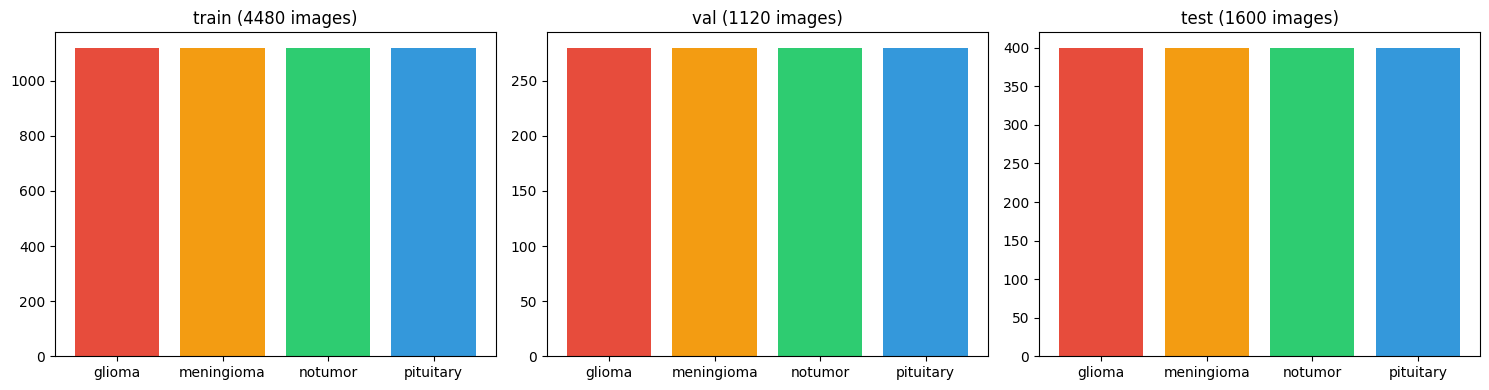

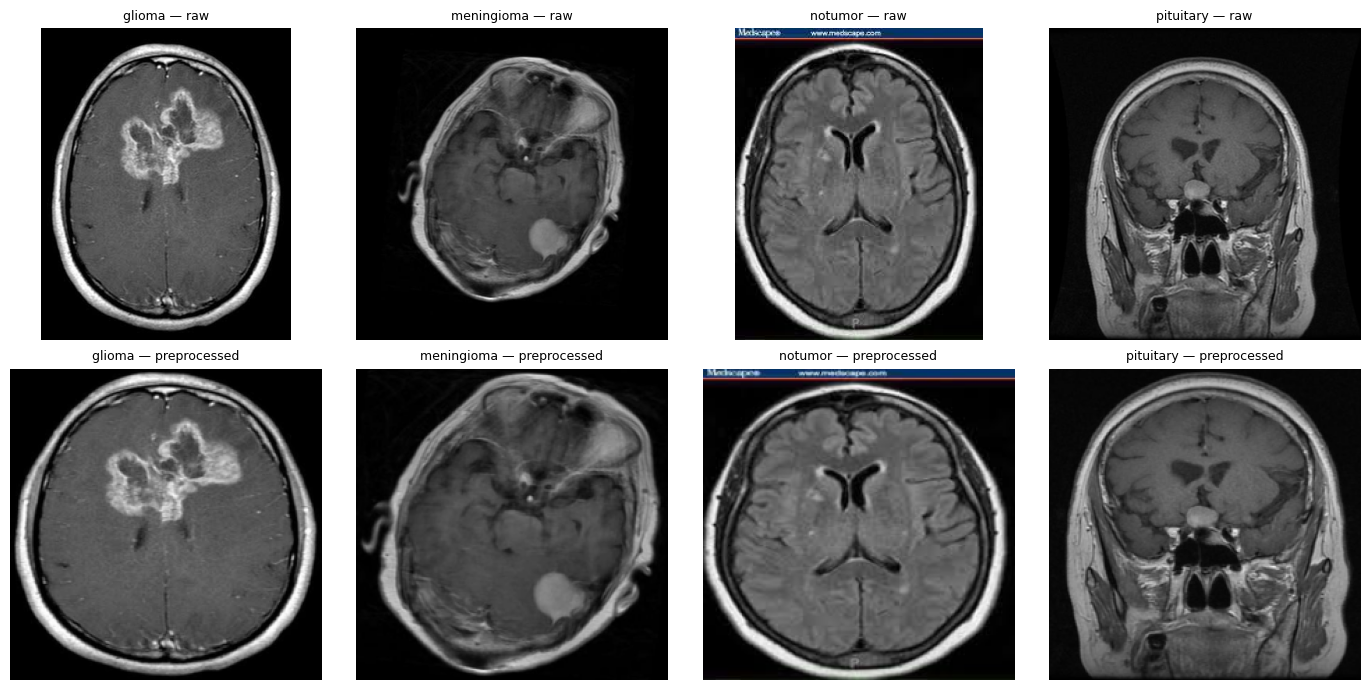

  [stage complete] eda


In [9]:
# ============================================================================
# STAGE 4 · EDA — class distribution + preprocessing demo (cached to disk)
# ============================================================================
stage = "eda"
if stage_done(stage):
    print("SKIP eda — plots already in results/plots/")
else:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, (name, paths) in zip(axes, {"train": split["train"], "val": split["val"],
                                        "test": split["test"]}.items()):
        cc = {c: sum(1 for p in paths if p.split("/")[1] == c) for c in Config.CLASS_NAMES}
        ax.bar(cc.keys(), cc.values(), color=["#e74c3c", "#f39c12", "#2ecc71", "#3498db"])
        ax.set_title(f"{name} ({sum(cc.values())} images)")
    plt.tight_layout()
    plt.savefig(Config.PLOTS_DIR / "dataset_distribution.png", dpi=200)
    plt.show()

    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    for j, c in enumerate(Config.CLASS_NAMES):
        src = next(DATA_DIR / p for p in split["test"] if p.split("/")[1] == c)
        raw = cv2.cvtColor(cv2.imread(str(src)), cv2.COLOR_BGR2RGB)
        proc = cv2.resize(remove_black_margins(raw.copy()), (224, 224),
                          interpolation=cv2.INTER_AREA)
        axes[0, j].imshow(raw);  axes[0, j].set_title(f"{c} — raw", fontsize=9)
        axes[1, j].imshow(proc); axes[1, j].set_title(f"{c} — preprocessed", fontsize=9)
        axes[0, j].axis("off");  axes[1, j].axis("off")
    plt.tight_layout()
    plt.savefig(Config.PLOTS_DIR / "preprocessing_demo.png", dpi=200)
    plt.show()
    mark_stage(stage)

## Stage 5 — training infrastructure (pure definitions)

Run this once per session. The five training cells that follow each train **one model, exactly once**:

- If `results/models/<model>/eval.json` exists → the cell prints the stored result and does nothing.
- If a training was interrupted → the cell **resumes** from the last completed epoch via `training_state.pt`.
- Otherwise it trains from scratch, evaluates once on the sealed test set, saves everything, and deletes the resume state.

First run downloads ImageNet-pretrained weights from HuggingFace (~16–22 MB per model; needs internet once). Honest per-model expectation on this i5-1155G7, measured: EfficientNet-B0 ≈ 10 min/epoch (≈4–6 h for 30 epochs, usually less with early stopping); MobileNetV3-Small several times faster; ViT-family models comparable to or slower than B0. Run the cells **one at a time**, in order — that is the point of the design.

In [10]:
# ============================================================================
# STAGE 5 · TRAINING INFRASTRUCTURE
#  · real sklearn metrics (the reference session silently ran with BROKEN
#    sklearn + homemade fallback metric code — every published number there
#    is an approximation; v2 fixes the environment instead)
#  · best-by-val-macro-F1 weights saved ATOMICALLY as a bare state_dict
#    (16-21 MB vs the original's 48-66 MB optimizer-blob checkpoints)
#  · resumable training_state.pt: interrupt a model mid-training, re-run
#    the same cell, and it CONTINUES from the saved epoch — never restarts
# ============================================================================
class EarlyStopping:
    def __init__(self, patience, min_delta):
        self.patience, self.min_delta = patience, min_delta
        self.best, self.count = -math.inf, 0
    def step(self, value):
        if value > self.best + self.min_delta:
            self.best, self.count = value, 0
            return True
        self.count += 1
        return False
    @property
    def triggered(self):
        return self.count >= self.patience
@torch.no_grad()
def collect_logits(model, loader):
    model.eval()
    logits, labels = [], []
    for xb, yb in loader:
        xb = xb.to(DEVICE).to(memory_format=torch.channels_last)
        logits.append(model(xb).cpu().numpy())
        labels.append(yb.numpy())
    return np.concatenate(logits), np.concatenate(labels)
def evaluate_model(model, loader):
    logits, labels = collect_logits(model, loader)
    probs = F.softmax(torch.from_numpy(logits), dim=1).numpy()
    preds = probs.argmax(1)
    roc = {}
    ybin = label_binarize(labels, classes=list(range(Config.NUM_CLASSES)))
    for i, c in enumerate(Config.CLASS_NAMES):
        fpr, tpr, _ = roc_curve(ybin[:, i], probs[:, i])
        step = max(1, len(fpr) // 100)
        roc[c] = {"fpr": fpr[::step].tolist(), "tpr": tpr[::step].tolist(),
                  "auc": float(auc(fpr, tpr))}
    return {
        "n_test": int(len(labels)),
        "accuracy": float(accuracy_score(labels, preds)),
        "precision_macro": float(precision_score(labels, preds, average="macro", zero_division=0)),
        "recall_macro": float(recall_score(labels, preds, average="macro", zero_division=0)),
        "f1_macro": float(f1_score(labels, preds, average="macro", zero_division=0)),
        "f1_weighted": float(f1_score(labels, preds, average="weighted", zero_division=0)),
        "per_class_precision": precision_score(labels, preds, average=None, zero_division=0).tolist(),
        "per_class_recall":    recall_score(labels, preds, average=None, zero_division=0).tolist(),
        "per_class_f1":        f1_score(labels, preds, average=None, zero_division=0).tolist(),
        "confusion_matrix": confusion_matrix(labels, preds).tolist(),
        "roc": roc,
        "classification_report": classification_report(
            labels, preds, target_names=Config.CLASS_NAMES, digits=4, zero_division=0),
    }
def plot_confusion(cm, title, path):
    cm = np.array(cm)
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(4), Config.CLASS_NAMES, rotation=30)
    ax.set_yticks(range(4), Config.CLASS_NAMES)
    thr = cm.max() / 2 if cm.max() > 0 else 0.5
    for i in range(4):
        for j in range(4):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                    color="white" if cm[i, j] > thr else "black")
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(title)
    fig.colorbar(im); plt.tight_layout()
    plt.savefig(path, dpi=300); plt.show()
def plot_roc(roc, title, path):
    fig, ax = plt.subplots(figsize=(6, 5))
    for c, d in roc.items():
        ax.plot(d["fpr"], d["tpr"], label=f"{c} (AUC {d['auc']:.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=0.8)
    ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
    ax.set_title(title); ax.legend(fontsize=8)
    plt.tight_layout(); plt.savefig(path, dpi=300); plt.show()
def plot_history(hist, title, path):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    ep = range(1, len(hist["train_loss"]) + 1)
    axes[0].plot(ep, hist["train_loss"], label="train")
    axes[0].plot(ep, hist["val_loss"], label="val")
    axes[0].set_title("Loss"); axes[0].legend()
    axes[1].plot(ep, hist["train_acc"], label="train")
    axes[1].plot(ep, hist["val_acc"], label="val")
    axes[1].set_title("Accuracy (%)"); axes[1].legend()
    axes[2].plot(ep, hist["val_f1"], color="green")
    axes[2].set_title("Val macro-F1")
    fig.suptitle(title)
    plt.tight_layout(); plt.savefig(path, dpi=200); plt.show()
class BaselineCNN(nn.Module):
    """The stupid-simple baseline every real model has to beat: three conv
    blocks and a linear head — ~90k parameters, no pretraining, no tricks.
    If a 90k-parameter CNN already captures most of the benchmark score,
    that says something about the benchmark, not about the big models."""
    def __init__(self, num_classes=4):
        super().__init__()
        def block(cin, cout):
            return nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1),
                                 nn.BatchNorm2d(cout), nn.ReLU(),
                                 nn.MaxPool2d(2))
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128),
                                      nn.AdaptiveAvgPool2d(1))
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(128, num_classes))
    def forward(self, x):
        return self.head(self.features(x))

def build_model(spec, pretrained=False):
    """Single model factory for the whole notebook: timm architectures are
    specified by their timm string, the BaselineCNN by the class itself."""
    if isinstance(spec, str):
        return timm.create_model(spec, pretrained=pretrained, num_classes=Config.NUM_CLASSES)
    return spec(num_classes=Config.NUM_CLASSES)

# the baseline lives next to the machinery that trains it, and is registered
# as a first-class model so every later stage treats it like the others
Config.MODELS = {"Baseline-CNN": (BaselineCNN, "CNN"), **Config.MODELS}

def train_one_model(display_name, timm_name, model_type, *, seed=None):
    mdir = Config.MODELS_DIR / display_name
    mdir.mkdir(parents=True, exist_ok=True)
    eval_path  = mdir / "eval.json"
    hist_path  = mdir / "history.json"
    w_path     = mdir / "best_weights.pth"
    state_path = mdir / "training_state.pt"
    if eval_path.exists():
        ev = json.loads(eval_path.read_text(encoding="utf-8"))
        print(f"SKIP {display_name}: already trained & evaluated — "
              f"test acc {ev['accuracy']*100:.2f}%, macro-F1 {ev['f1_macro']:.4f}")
        return
    print("\n" + "=" * 70)
    spec_name = timm_name if isinstance(timm_name, str) else timm_name.__name__
    print(f"TRAINING {display_name} ({spec_name}) on {DEVICE} — resumable, run once")
    print("=" * 70)
    set_seed(seed if seed is not None else Config.SEED)   # per-model reseed; the
    # seed-stability stage re-trains the best model at seeds 43/44 through this
    model = build_model(timm_name, pretrained=True)
    model = model.to(DEVICE).to(memory_format=torch.channels_last)
    optimizer = torch.optim.AdamW(model.parameters(), lr=Config.LEARNING_RATE,
                                  weight_decay=Config.WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,
                                                           T_max=Config.SCHEDULER_T_MAX)
    criterion = nn.CrossEntropyLoss()   # UNWEIGHTED — balancing lives in the sampler only
    stopper = EarlyStopping(Config.EARLY_STOP_PATIENCE, Config.EARLY_STOP_MIN_DELTA)
    start_epoch, best_f1 = 1, -1.0
    if state_path.exists():
        st = torch.load(state_path, map_location=DEVICE, weights_only=False)
        model.load_state_dict(st["model"])
        optimizer.load_state_dict(st["optimizer"])
        scheduler.load_state_dict(st["scheduler"])
        hist = st["history"]
        start_epoch, best_f1 = st["epoch"] + 1, st["best_f1"]
        stopper.best, stopper.count = best_f1, st["patience_count"]
        print(f"  RESUMED from epoch {start_epoch} (best val macro-F1 so far {best_f1:.4f})")
    else:
        hist = {"train_loss": [], "train_acc": [], "val_loss": [],
                "val_acc": [], "val_f1": [], "lr": []}
    t_start = time.time()
    interrupted = False
    for epoch in range(start_epoch, Config.EPOCHS + 1):
        try:
            model.train()
            tl, tn, tcorrect = 0.0, 0, 0
            for xb, yb in train_loader:
                xb = xb.to(DEVICE).to(memory_format=torch.channels_last)
                yb = yb.to(DEVICE)
                optimizer.zero_grad()
                out = model(xb)
                loss = criterion(out, yb)
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), Config.GRAD_CLIP)
                optimizer.step()
                tl += loss.item() * yb.size(0)
                tn += yb.size(0)
                tcorrect += (out.argmax(1) == yb).sum().item()
            train_loss, train_acc = tl / tn, 100.0 * tcorrect / tn
            vlog, vlab = collect_logits(model, val_loader)
            vpred = vlog.argmax(1)
            val_loss = float(F.cross_entropy(torch.from_numpy(vlog), torch.from_numpy(vlab)))
            val_acc = 100.0 * float((vpred == vlab).mean())
            val_f1 = float(f1_score(vlab, vpred, average="macro"))
            lr_now = optimizer.param_groups[0]["lr"]
            hist["train_loss"].append(train_loss); hist["train_acc"].append(train_acc)
            hist["val_loss"].append(val_loss);     hist["val_acc"].append(val_acc)
            hist["val_f1"].append(val_f1);        hist["lr"].append(lr_now)
            per_epoch = (time.time() - t_start) / (epoch - start_epoch + 1)
            eta_min = per_epoch * (Config.EPOCHS - epoch) / 60
            print(f"  Epoch {epoch:02d}/{Config.EPOCHS} | train {train_loss:.4f}/{train_acc:.2f}% "
                  f"| val {val_loss:.4f}/{val_acc:.2f}% | valF1 {val_f1:.4f} "
                  f"| lr {lr_now:.2e} | ETA {eta_min:.0f} min", flush=True)
            if stopper.step(val_f1):
                best_f1 = val_f1
                atomic_save_state({"model": model.state_dict()}, w_path)
                print(f"    * new best — weights saved (val macro-F1 {val_f1:.4f})")
            atomic_save_state({"model": model.state_dict(),
                               "optimizer": optimizer.state_dict(),
                               "scheduler": scheduler.state_dict(),
                               "history": hist, "epoch": epoch, "best_f1": best_f1,
                               "patience_count": stopper.count}, state_path)
            atomic_write_json(hist_path, hist)
            scheduler.step()
            if stopper.triggered:
                print(f"  early stopping at epoch {epoch} "
                      f"(no improvement for {stopper.patience} epochs)")
                break
        except KeyboardInterrupt:
            print(f"\n  INTERRUPTED at epoch {epoch} — state saved; "
                  "re-run this cell to RESUME (it will NOT restart)")
            interrupted = True
            break
    if interrupted:
        return
    # Final: reload best weights, evaluate ONCE on the sealed test set.
    model.load_state_dict(torch.load(w_path, map_location=DEVICE, weights_only=False)["model"])
    ev = evaluate_model(model, test_loader)
    params = sum(p.numel() for p in model.parameters())
    ev.update({
        "model": display_name, "timm_name": spec_name, "model_type": model_type,
        "params": int(params), "size_mb": round(params * 4 / 1e6, 2),
        "best_epoch": int(np.argmax(hist["val_f1"]) + 1),
        "best_val_f1": float(max(hist["val_f1"])),
        "epochs_run": len(hist["val_f1"]),
        "device": str(DEVICE), "seed": seed if seed is not None else Config.SEED,
        "batch_size": Config.BATCH_SIZE,
        "trained_at": datetime.now().isoformat(timespec="seconds"),
    })
    atomic_write_json(eval_path, ev)
    plot_confusion(ev["confusion_matrix"], f"{display_name} — confusion matrix (test)",
                   Config.PLOTS_DIR / f"{display_name}_confusion_matrix.png")
    plot_roc(ev["roc"], f"{display_name} — per-class ROC (test)",
             Config.PLOTS_DIR / f"{display_name}_roc_curves.png")
    plot_history(hist, f"{display_name} — training curves",
                 Config.PLOTS_DIR / f"{display_name}_training_curves.png")
    print(ev["classification_report"])
    print(f"DONE {display_name} | test accuracy {ev['accuracy']*100:.2f}% "
          f"| macro-F1 {ev['f1_macro']:.4f} | best epoch {ev['best_epoch']}")
    state_path.unlink(missing_ok=True)   # training complete — resume state no longer needed
    mark_stage(f"train:{display_name}",
               {"test_acc": ev["accuracy"], "f1_macro": ev["f1_macro"]})

## Stage 6 — training, one model at a time (run these cells in order)

Each cell below is independent and safe to re-run: finished models are skipped, interrupted models resume, nothing ever starts over. Expect overnight-scale total wall-clock on this CPU.


TRAINING Baseline-CNN (BaselineCNN) on cuda — resumable, run once
  Epoch 01/30 | train 1.2881/37.95% | val 1.1468/52.95% | valF1 0.5154 | lr 1.00e-04 | ETA 14 min
    * new best — weights saved (val macro-F1 0.5154)
  Epoch 02/30 | train 1.2333/42.21% | val 1.0636/60.98% | valF1 0.6086 | lr 9.97e-05 | ETA 13 min
    * new best — weights saved (val macro-F1 0.6086)
  Epoch 03/30 | train 1.1993/45.09% | val 1.0542/62.50% | valF1 0.6219 | lr 9.89e-05 | ETA 13 min
    * new best — weights saved (val macro-F1 0.6219)
  Epoch 04/30 | train 1.1937/45.38% | val 1.0478/60.62% | valF1 0.6066 | lr 9.76e-05 | ETA 12 min
  Epoch 05/30 | train 1.1872/46.50% | val 1.0313/65.27% | valF1 0.6460 | lr 9.57e-05 | ETA 12 min
    * new best — weights saved (val macro-F1 0.6460)
  Epoch 06/30 | train 1.1697/48.10% | val 1.0083/58.39% | valF1 0.5746 | lr 9.33e-05 | ETA 11 min
  Epoch 07/30 | train 1.1631/48.30% | val 1.0015/55.71% | valF1 0.5417 | lr 9.05e-05 | ETA 11 min
  Epoch 08/30 | train 1.1557/48.84%

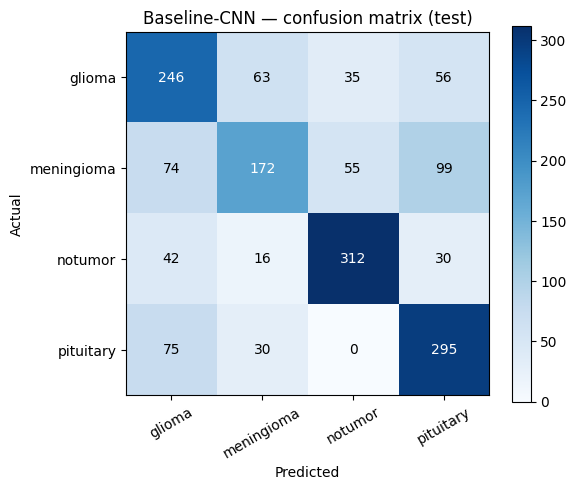

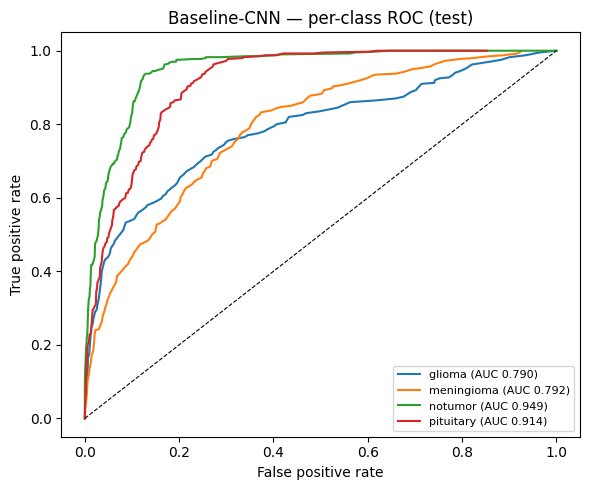

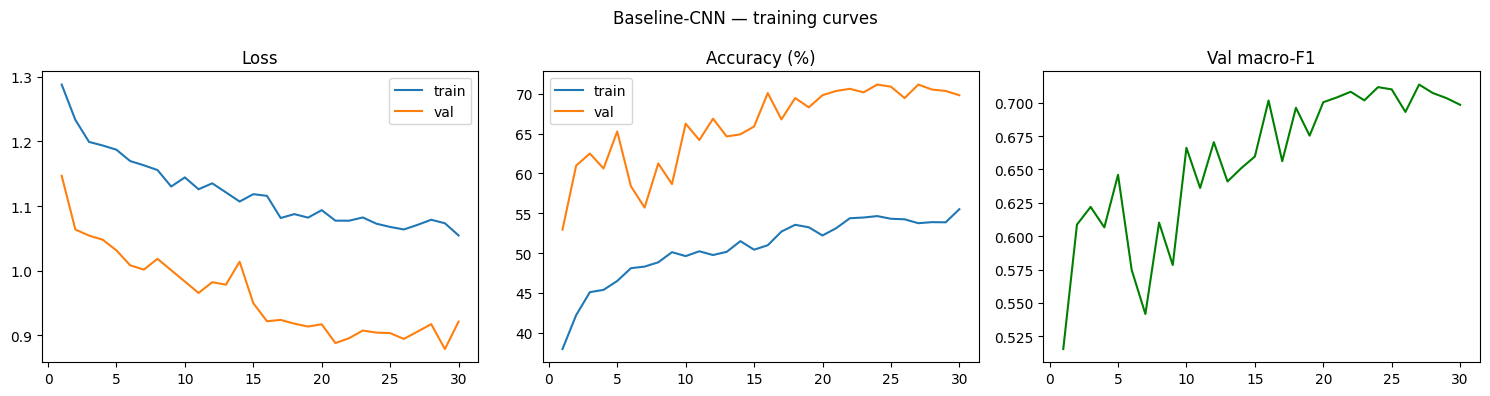

              precision    recall  f1-score   support

      glioma     0.5629    0.6150    0.5878       400
  meningioma     0.6121    0.4300    0.5051       400
     notumor     0.7761    0.7800    0.7781       400
   pituitary     0.6146    0.7375    0.6705       400

    accuracy                         0.6406      1600
   macro avg     0.6414    0.6406    0.6354      1600
weighted avg     0.6414    0.6406    0.6354      1600

DONE Baseline-CNN | test accuracy 64.06% | macro-F1 0.6354 | best epoch 27
  [stage complete] train:Baseline-CNN


In [11]:
# ============================================================================
# STAGE 6a · MODEL 1/6 — Baseline-CNN  (the reference point)
# ~90k parameters, three conv blocks, no pretraining. Every architecture
# below has to justify its complexity against this number.
# ============================================================================
train_one_model("Baseline-CNN", BaselineCNN, "CNN")



TRAINING EfficientNet-B0 (efficientnet_b0) on cuda — resumable, run once


model.safetensors:   0%|          | 0.00/21.4M [00:00<?, ?B/s]

  Epoch 01/30 | train 1.1453/67.46% | val 0.5748/86.96% | valF1 0.8689 | lr 1.00e-04 | ETA 24 min
    * new best — weights saved (val macro-F1 0.8689)
  Epoch 02/30 | train 0.6477/80.38% | val 0.3382/92.50% | valF1 0.9253 | lr 9.97e-05 | ETA 21 min
    * new best — weights saved (val macro-F1 0.9253)
  Epoch 03/30 | train 0.4437/86.38% | val 0.2232/94.55% | valF1 0.9459 | lr 9.89e-05 | ETA 19 min
    * new best — weights saved (val macro-F1 0.9459)
  Epoch 04/30 | train 0.3493/88.50% | val 0.1538/95.98% | valF1 0.9598 | lr 9.76e-05 | ETA 18 min
    * new best — weights saved (val macro-F1 0.9598)
  Epoch 05/30 | train 0.3188/90.00% | val 0.1323/96.52% | valF1 0.9654 | lr 9.57e-05 | ETA 18 min
    * new best — weights saved (val macro-F1 0.9654)
  Epoch 06/30 | train 0.2405/92.59% | val 0.0986/97.32% | valF1 0.9733 | lr 9.33e-05 | ETA 17 min
    * new best — weights saved (val macro-F1 0.9733)
  Epoch 07/30 | train 0.2046/93.64% | val 0.1102/97.23% | valF1 0.9725 | lr 9.05e-05 | ETA 16 

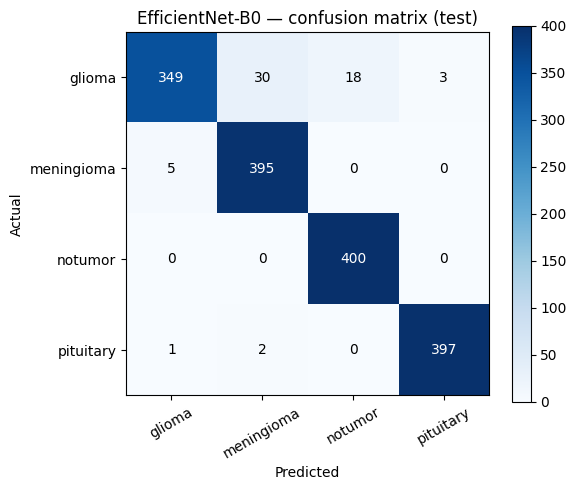

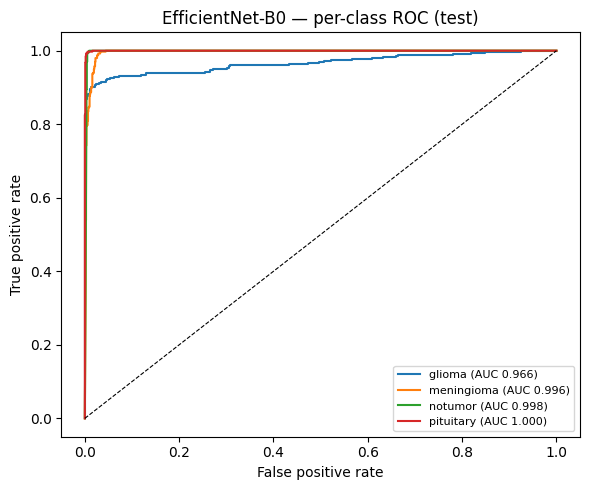

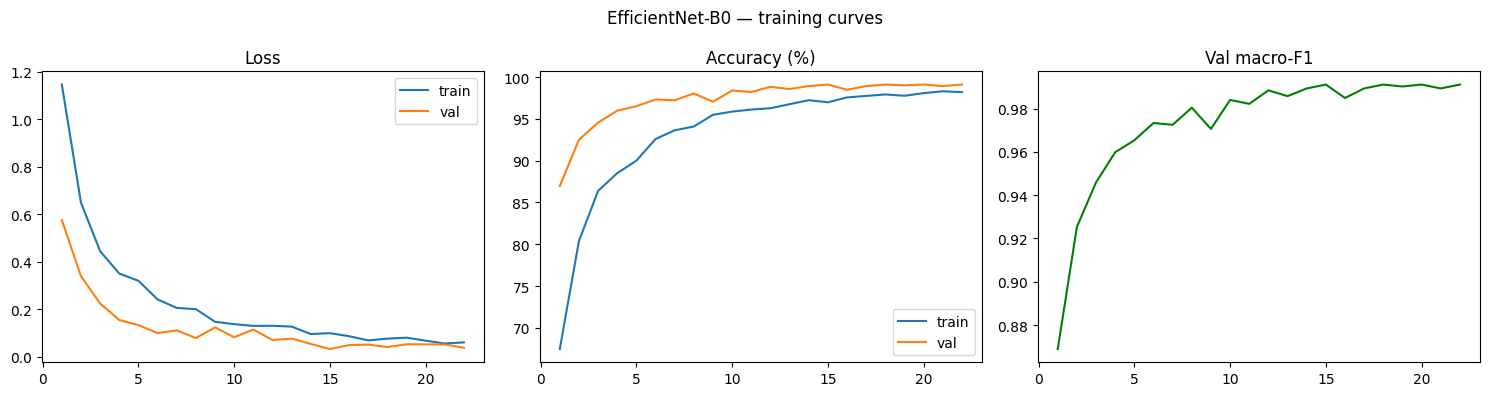

              precision    recall  f1-score   support

      glioma     0.9831    0.8725    0.9245       400
  meningioma     0.9251    0.9875    0.9553       400
     notumor     0.9569    1.0000    0.9780       400
   pituitary     0.9925    0.9925    0.9925       400

    accuracy                         0.9631      1600
   macro avg     0.9644    0.9631    0.9626      1600
weighted avg     0.9644    0.9631    0.9626      1600

DONE EfficientNet-B0 | test accuracy 96.31% | macro-F1 0.9626 | best epoch 15
  [stage complete] train:EfficientNet-B0


In [12]:
# ============================================================================
# STAGE 6b · MODEL 2/6 — EfficientNet-B0  (the CNN workhorse)
# ============================================================================
train_one_model("EfficientNet-B0", "efficientnet_b0", "CNN")


TRAINING MobileNetV3-Small (mobilenetv3_small_100) on cuda — resumable, run once


model.safetensors:   0%|          | 0.00/10.2M [00:00<?, ?B/s]

  Epoch 01/30 | train 1.2279/68.57% | val 0.4671/85.80% | valF1 0.8577 | lr 1.00e-04 | ETA 17 min
    * new best — weights saved (val macro-F1 0.8577)
  Epoch 02/30 | train 0.6070/81.03% | val 0.2053/92.77% | valF1 0.9281 | lr 9.97e-05 | ETA 15 min
    * new best — weights saved (val macro-F1 0.9281)
  Epoch 03/30 | train 0.4742/85.09% | val 0.2327/92.23% | valF1 0.9214 | lr 9.89e-05 | ETA 14 min
  Epoch 04/30 | train 0.3711/87.90% | val 0.3454/90.62% | valF1 0.9079 | lr 9.76e-05 | ETA 13 min
  Epoch 05/30 | train 0.3442/88.86% | val 0.2156/93.12% | valF1 0.9307 | lr 9.57e-05 | ETA 12 min
    * new best — weights saved (val macro-F1 0.9307)
  Epoch 06/30 | train 0.2876/90.98% | val 0.1889/95.36% | valF1 0.9535 | lr 9.33e-05 | ETA 12 min
    * new best — weights saved (val macro-F1 0.9535)
  Epoch 07/30 | train 0.2540/91.88% | val 0.1209/96.07% | valF1 0.9608 | lr 9.05e-05 | ETA 11 min
    * new best — weights saved (val macro-F1 0.9608)
  Epoch 08/30 | train 0.2325/92.39% | val 0.0797/

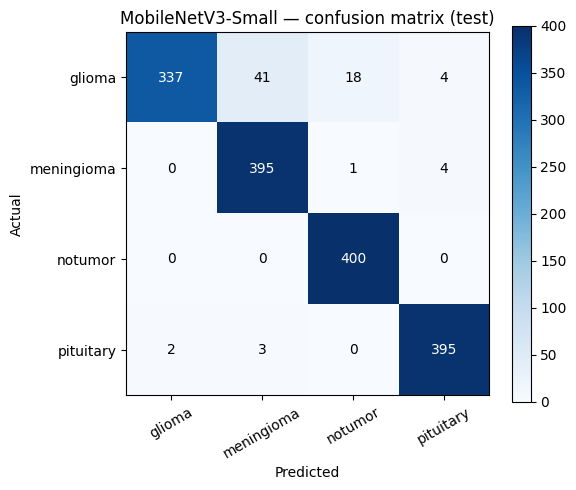

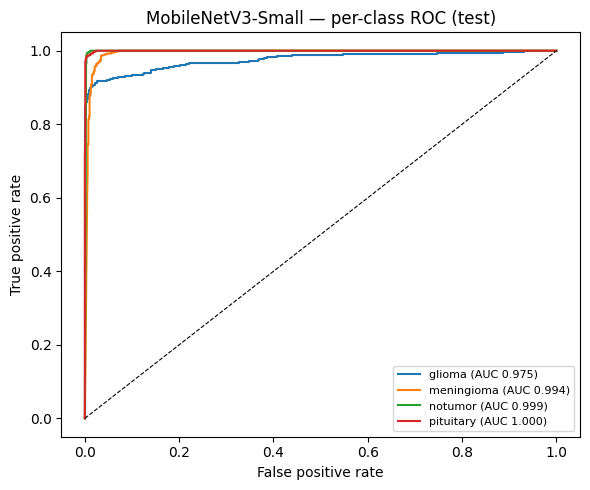

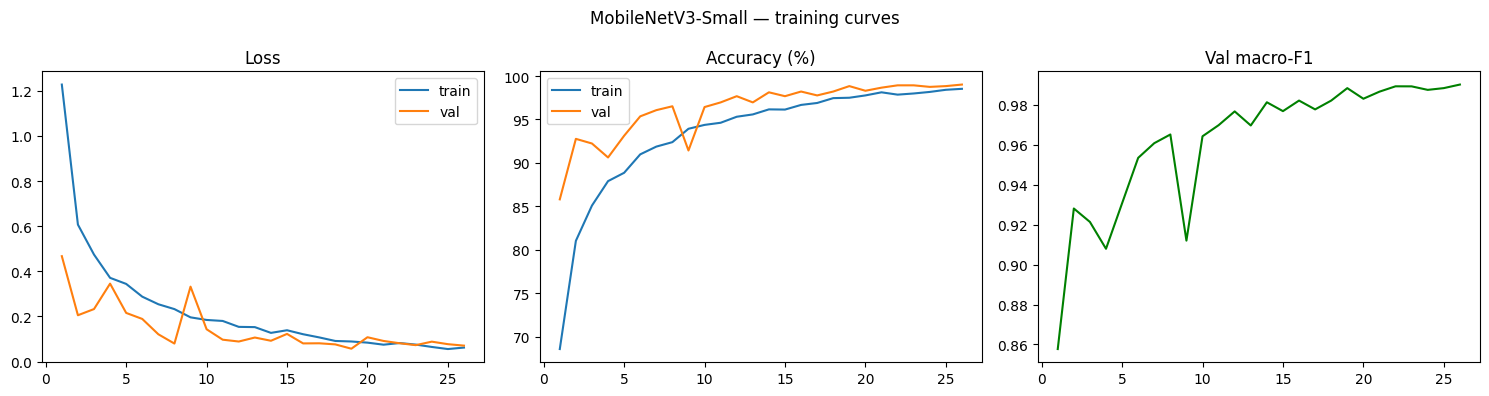

              precision    recall  f1-score   support

      glioma     0.9941    0.8425    0.9120       400
  meningioma     0.8998    0.9875    0.9416       400
     notumor     0.9547    1.0000    0.9768       400
   pituitary     0.9801    0.9875    0.9838       400

    accuracy                         0.9544      1600
   macro avg     0.9572    0.9544    0.9536      1600
weighted avg     0.9572    0.9544    0.9536      1600

DONE MobileNetV3-Small | test accuracy 95.44% | macro-F1 0.9536 | best epoch 26
  [stage complete] train:MobileNetV3-Small


In [13]:
# ============================================================================
# STAGE 6c · MODEL 3/6 — MobileNetV3-Small  (smallest real model)
# ============================================================================
train_one_model("MobileNetV3-Small", "mobilenetv3_small_100", "CNN")


TRAINING MobileViT-S (mobilevit_s) on cuda — resumable, run once


model.safetensors:   0%|          | 0.00/22.4M [00:00<?, ?B/s]

  Epoch 01/30 | train 0.8659/70.33% | val 0.3568/88.04% | valF1 0.8820 | lr 1.00e-04 | ETA 30 min
    * new best — weights saved (val macro-F1 0.8820)
  Epoch 02/30 | train 0.4580/84.08% | val 0.2166/92.68% | valF1 0.9259 | lr 9.97e-05 | ETA 29 min
    * new best — weights saved (val macro-F1 0.9259)
  Epoch 03/30 | train 0.3649/87.70% | val 0.1571/94.73% | valF1 0.9472 | lr 9.89e-05 | ETA 27 min
    * new best — weights saved (val macro-F1 0.9472)
  Epoch 04/30 | train 0.3082/89.53% | val 0.1106/96.25% | valF1 0.9626 | lr 9.76e-05 | ETA 26 min
    * new best — weights saved (val macro-F1 0.9626)
  Epoch 05/30 | train 0.2599/91.67% | val 0.0921/97.14% | valF1 0.9715 | lr 9.57e-05 | ETA 25 min
    * new best — weights saved (val macro-F1 0.9715)
  Epoch 06/30 | train 0.2021/93.19% | val 0.0754/97.32% | valF1 0.9733 | lr 9.33e-05 | ETA 24 min
  Epoch 07/30 | train 0.2065/93.37% | val 0.0813/97.14% | valF1 0.9715 | lr 9.05e-05 | ETA 23 min
  Epoch 08/30 | train 0.1771/94.31% | val 0.0795/

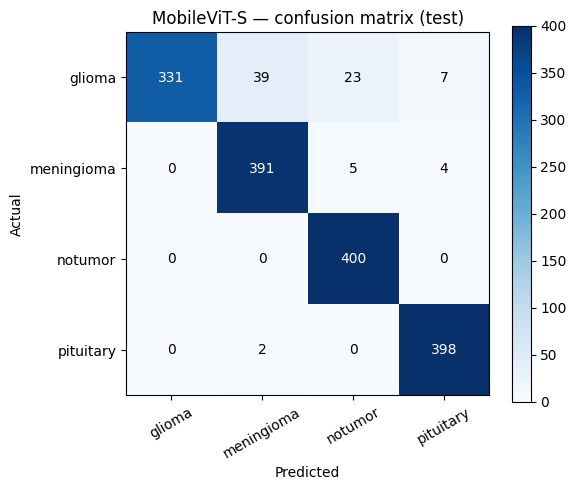

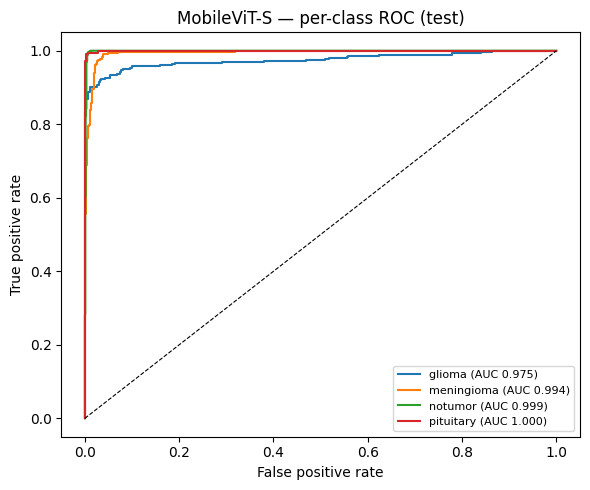

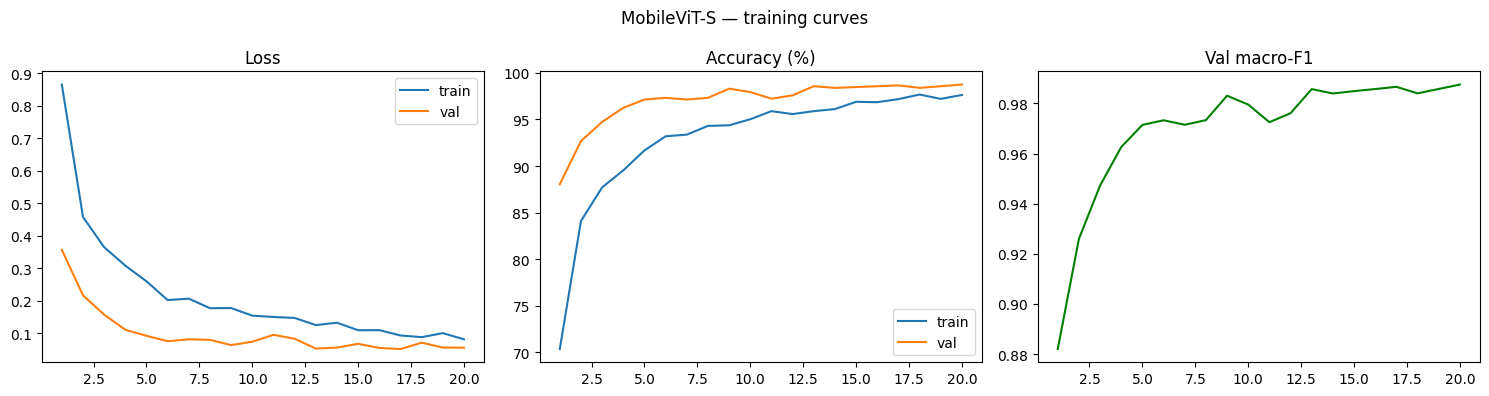

              precision    recall  f1-score   support

      glioma     1.0000    0.8275    0.9056       400
  meningioma     0.9051    0.9775    0.9399       400
     notumor     0.9346    1.0000    0.9662       400
   pituitary     0.9731    0.9950    0.9839       400

    accuracy                         0.9500      1600
   macro avg     0.9532    0.9500    0.9489      1600
weighted avg     0.9532    0.9500    0.9489      1600

DONE MobileViT-S | test accuracy 95.00% | macro-F1 0.9489 | best epoch 20
  [stage complete] train:MobileViT-S


In [14]:
# ============================================================================
# STAGE 6d · MODEL 4/6 — MobileViT-S  (hybrid conv+transformer)
# ============================================================================
train_one_model("MobileViT-S", "mobilevit_s", "Hybrid ViT")


TRAINING DeiT-Tiny (deit_tiny_patch16_224) on cuda — resumable, run once


model.safetensors:   0%|          | 0.00/22.9M [00:00<?, ?B/s]

  Epoch 01/30 | train 0.5581/77.81% | val 0.2282/91.34% | valF1 0.9129 | lr 1.00e-04 | ETA 14 min
    * new best — weights saved (val macro-F1 0.9129)
  Epoch 02/30 | train 0.3406/87.68% | val 0.1873/93.39% | valF1 0.9343 | lr 9.97e-05 | ETA 13 min
    * new best — weights saved (val macro-F1 0.9343)
  Epoch 03/30 | train 0.2702/90.36% | val 0.1299/96.16% | valF1 0.9616 | lr 9.89e-05 | ETA 13 min
    * new best — weights saved (val macro-F1 0.9616)
  Epoch 04/30 | train 0.2654/90.69% | val 0.1385/94.38% | valF1 0.9433 | lr 9.76e-05 | ETA 12 min
  Epoch 05/30 | train 0.2150/92.90% | val 0.0942/96.70% | valF1 0.9670 | lr 9.57e-05 | ETA 12 min
    * new best — weights saved (val macro-F1 0.9670)
  Epoch 06/30 | train 0.2346/92.14% | val 0.1503/95.18% | valF1 0.9515 | lr 9.33e-05 | ETA 11 min
  Epoch 07/30 | train 0.2029/93.12% | val 0.1306/94.64% | valF1 0.9466 | lr 9.05e-05 | ETA 11 min
  Epoch 08/30 | train 0.1684/94.33% | val 0.0930/97.23% | valF1 0.9723 | lr 8.72e-05 | ETA 10 min
    

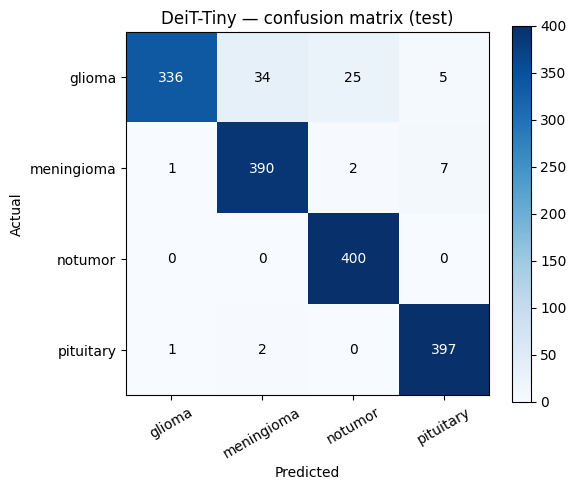

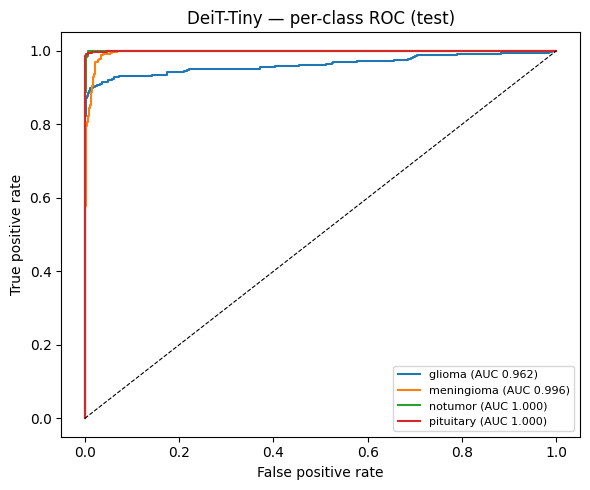

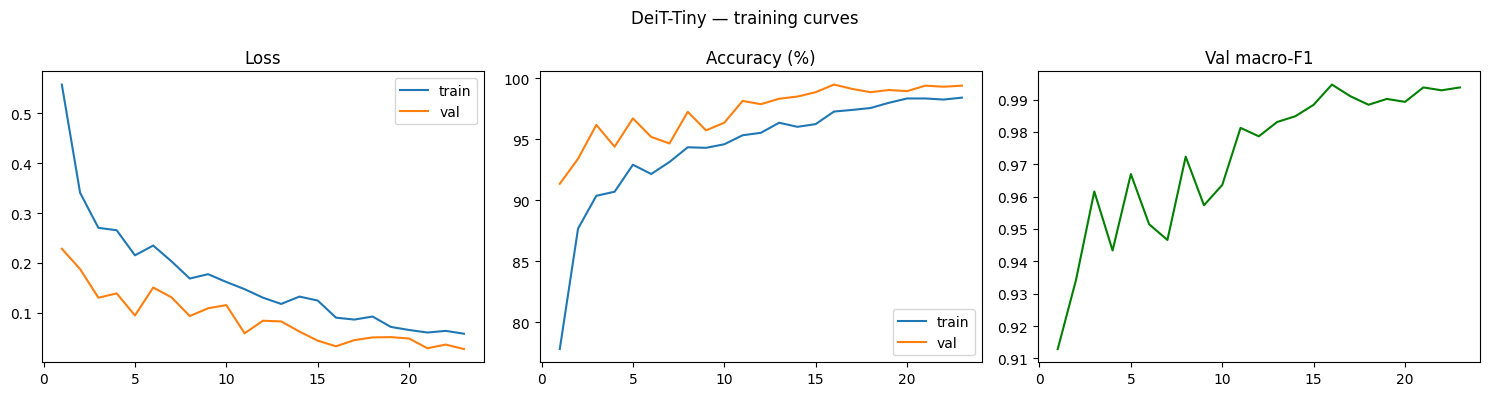

              precision    recall  f1-score   support

      glioma     0.9941    0.8400    0.9106       400
  meningioma     0.9155    0.9750    0.9443       400
     notumor     0.9368    1.0000    0.9674       400
   pituitary     0.9707    0.9925    0.9815       400

    accuracy                         0.9519      1600
   macro avg     0.9543    0.9519    0.9509      1600
weighted avg     0.9543    0.9519    0.9509      1600

DONE DeiT-Tiny | test accuracy 95.19% | macro-F1 0.9509 | best epoch 16
  [stage complete] train:DeiT-Tiny


In [15]:
# ============================================================================
# STAGE 6e · MODEL 5/6 — DeiT-Tiny  (reference run's best model)
# ============================================================================
train_one_model("DeiT-Tiny", "deit_tiny_patch16_224", "ViT")


TRAINING TinyViT-5M (tiny_vit_5m_224) on cuda — resumable, run once


model.safetensors:   0%|          | 0.00/48.4M [00:00<?, ?B/s]

  Epoch 01/30 | train 0.6587/76.65% | val 0.2092/93.30% | valF1 0.9334 | lr 1.00e-04 | ETA 24 min
    * new best — weights saved (val macro-F1 0.9334)
  Epoch 02/30 | train 0.3030/89.53% | val 0.1508/95.00% | valF1 0.9500 | lr 9.97e-05 | ETA 23 min
    * new best — weights saved (val macro-F1 0.9500)
  Epoch 03/30 | train 0.2405/91.85% | val 0.0972/96.79% | valF1 0.9679 | lr 9.89e-05 | ETA 21 min
    * new best — weights saved (val macro-F1 0.9679)
  Epoch 04/30 | train 0.1934/93.75% | val 0.1017/96.43% | valF1 0.9644 | lr 9.76e-05 | ETA 21 min
  Epoch 05/30 | train 0.1867/93.95% | val 0.1289/95.71% | valF1 0.9572 | lr 9.57e-05 | ETA 20 min
  Epoch 06/30 | train 0.1382/95.71% | val 0.0586/98.30% | valF1 0.9831 | lr 9.33e-05 | ETA 19 min
    * new best — weights saved (val macro-F1 0.9831)
  Epoch 07/30 | train 0.1347/95.47% | val 0.0589/97.77% | valF1 0.9777 | lr 9.05e-05 | ETA 18 min
  Epoch 08/30 | train 0.1156/96.43% | val 0.0426/98.93% | valF1 0.9893 | lr 8.72e-05 | ETA 17 min
    

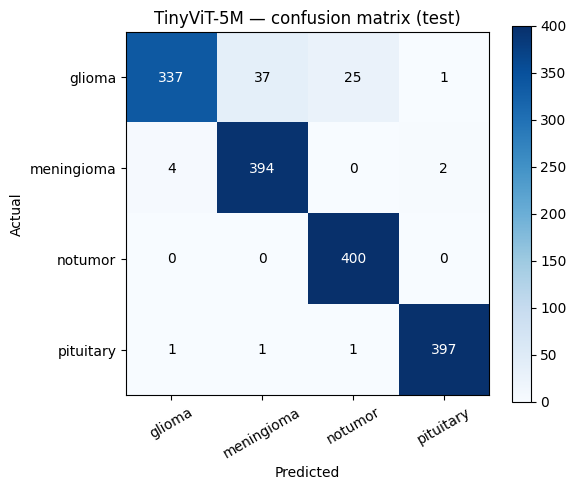

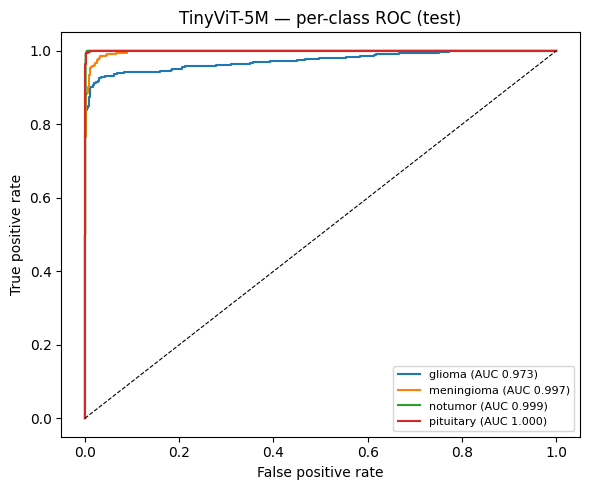

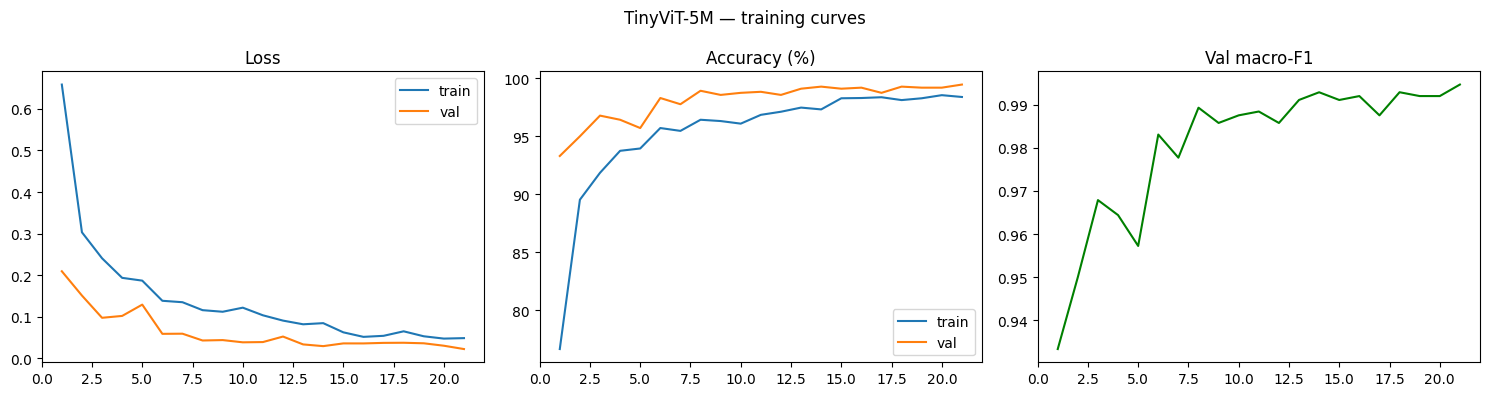

              precision    recall  f1-score   support

      glioma     0.9854    0.8425    0.9084       400
  meningioma     0.9120    0.9850    0.9471       400
     notumor     0.9390    1.0000    0.9685       400
   pituitary     0.9925    0.9925    0.9925       400

    accuracy                         0.9550      1600
   macro avg     0.9572    0.9550    0.9541      1600
weighted avg     0.9572    0.9550    0.9541      1600

DONE TinyViT-5M | test accuracy 95.50% | macro-F1 0.9541 | best epoch 21
  [stage complete] train:TinyViT-5M


In [16]:
# ============================================================================
# STAGE 6f · MODEL 6/6 — TinyViT-5M
# ============================================================================
train_one_model("TinyViT-5M", "tiny_vit_5m_224", "ViT")

## Stage 7 — comparison (rebuilt from per-model JSONs — duplicates impossible)

,Model,Type,Params (M),Size (MB),Accuracy (%),Macro-F1,Macro-P,Macro-R,Best epoch
0,EfficientNet-B0,CNN,4.01,16.05,96.31,0.9626,0.9644,0.9631,15
1,TinyViT-5M,ViT,5.07,20.29,95.50,0.9541,0.9572,0.9550,21
2,MobileNetV3-Small,CNN,1.52,6.09,95.44,0.9536,0.9572,0.9544,26
3,DeiT-Tiny,ViT,5.53,22.10,95.19,0.9509,0.9543,0.9519,16
4,MobileViT-S,Hybrid ViT,4.94,19.76,95.00,0.9489,0.9532,0.9500,20
5,Baseline-CNN,CNN,0.09,0.38,64.06,0.6354,0.6414,0.6406,27



BEST MODEL: EfficientNet-B0 — test acc 96.31%, macro-F1 0.9626


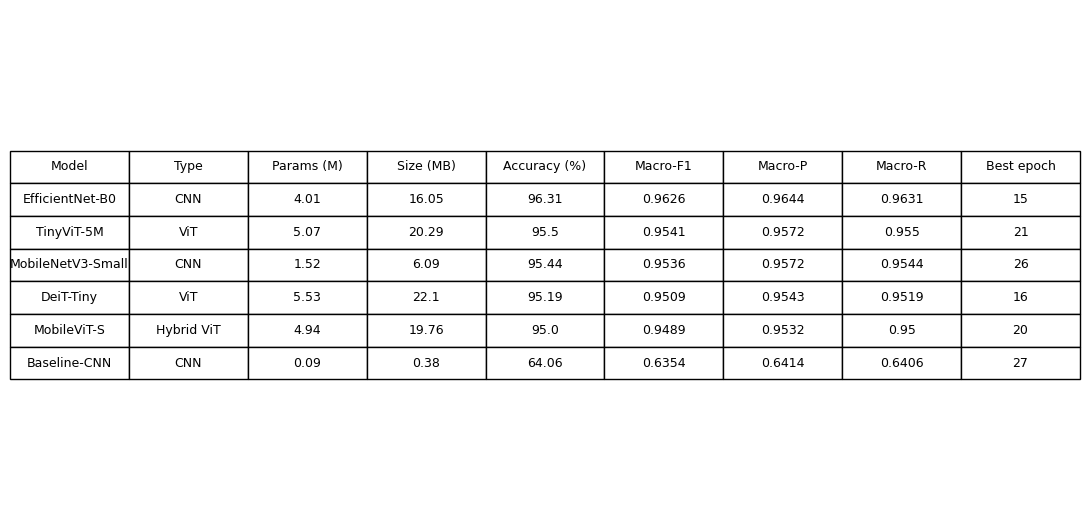


v2 vs reference run (Azure CPU, batch 8, double-balanced, fallback metrics):


,Model,Accuracy (%),reference_acc,delta_pp
0,EfficientNet-B0,96.31,98.93,-2.62
1,TinyViT-5M,95.50,99.24,-3.74
2,MobileNetV3-Small,95.44,98.78,-3.34
3,DeiT-Tiny,95.19,99.31,-4.12
4,MobileViT-S,95.00,98.86,-3.86
5,Baseline-CNN,64.06,NaN,NaN


  [stage complete] comparison


In [17]:
# ============================================================================
# STAGE 7 · COMPARISON TABLE
# The original appended results across sessions, producing a 6-row table for
# 5 models (two MobileViT-S rows at 98.93% and 98.32%). v2 rebuilds the table
# FRESH from one JSON per model, in ONE unified schema — a duplicate row is
# structurally impossible, and the "Automated Analysis" that crashed in the
# original (KeyError: 'f1_score' — three schemas coexisted) completes here.
# ============================================================================
rows, missing = [], []
for name, (timm_name, mtype) in Config.MODELS.items():
    p = Config.MODELS_DIR / name / "eval.json"
    if p.exists():
        ev = json.loads(p.read_text(encoding="utf-8"))
        rows.append({"Model": name, "Type": mtype,
                     "Params (M)": round(ev["params"] / 1e6, 2),
                     "Size (MB)": ev["size_mb"],
                     "Accuracy (%)": round(ev["accuracy"] * 100, 2),
                     "Macro-F1": round(ev["f1_macro"], 4),
                     "Macro-P": round(ev["precision_macro"], 4),
                     "Macro-R": round(ev["recall_macro"], 4),
                     "Best epoch": ev["best_epoch"]})
    else:
        missing.append(name)

df = pd.DataFrame(rows).sort_values("Macro-F1", ascending=False).reset_index(drop=True)
if missing:
    print("Not yet trained:", missing, "— run their training cells first; "
          "the table below shows what exists so far.")
display(df)

if len(df) == len(Config.MODELS):
    atomic_write_json(Config.RESULTS_DIR / "model_comparison.json", df.to_dict("records"))
    df.to_csv(Config.RESULTS_DIR / "model_comparison.csv", index=False)
    best = df.iloc[0]
    print(f"\nBEST MODEL: {best['Model']} — test acc {best['Accuracy (%)']}%, "
          f"macro-F1 {best['Macro-F1']}")

    fig, ax = plt.subplots(figsize=(11, 0.7 * len(df) + 1.2))
    ax.axis("off")
    tbl = ax.table(cellText=df.astype(str).values, colLabels=df.columns,
                   loc="center", cellLoc="center")
    tbl.auto_set_font_size(False); tbl.set_fontsize(9); tbl.scale(1, 1.6)
    plt.tight_layout()
    plt.savefig(Config.PLOTS_DIR / "model_comparison_table.png", dpi=200,
                bbox_inches="tight")
    plt.show()

    REFERENCE = {   # canonical Azure CPU run (Nov 2025) — context only, see README
        "DeiT-Tiny": 99.31, "TinyViT-5M": 99.24, "EfficientNet-B0": 98.93,
        "MobileViT-S": 98.86, "MobileNetV3-Small": 98.78,
    }
    cmp = df.assign(reference_acc=df["Model"].map(REFERENCE))
    cmp["delta_pp"] = (cmp["Accuracy (%)"] - cmp["reference_acc"]).round(2)
    print("\nv2 vs reference run (Azure CPU, batch 8, double-balanced, fallback metrics):")
    display(cmp[["Model", "Accuracy (%)", "reference_acc", "delta_pp"]])
    mark_stage("comparison", {"best": best["Model"]})

## Stage 8 — explainability (Grad-CAM, done right)

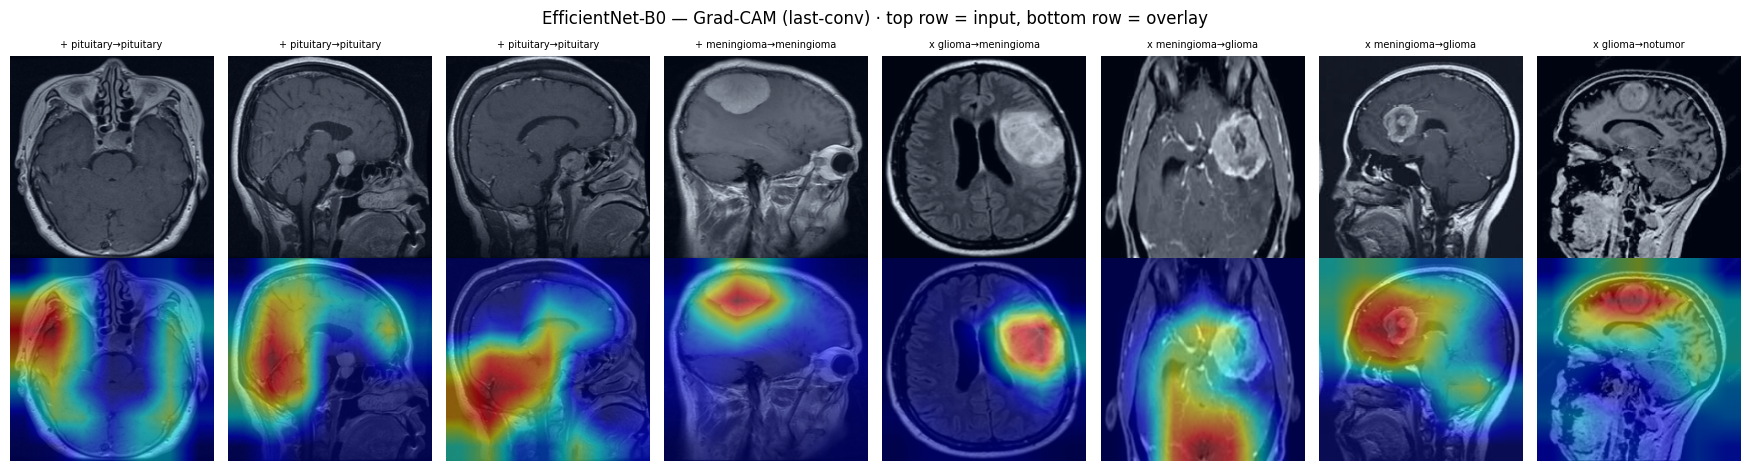

  EfficientNet-B0: explained 8 seeded test samples (1541/1600 correct overall)
  failure profile (EfficientNet-B0): true→pred confusion concentrates in glioma→meningioma (30), glioma→notumor (18), meningioma→glioma (5), glioma→pituitary (3)
  [stage complete] explain


In [18]:
# ============================================================================
# STAGE 8 · EXPLAINABILITY — Grad-CAM via the pytorch-grad-cam library
# Fixes vs the original: deprecated register_backward_hook → maintained
# library; applied to the ACTUAL best model (the original ran it on
# all_results[0] = EfficientNet regardless of the winner); plain ViTs get
# the accepted reshape-transform treatment (raw Grad-CAM is invalid on ViT
# activations); sample selection SEEDED (the original used unseeded
# np.random.choice — its figures were unrepeatable).
# ============================================================================
stage = "explain"
if stage_done(stage):
    print("SKIP explain — Grad-CAM outputs in results/plots/")
else:
    from pytorch_grad_cam import GradCAM as PGGradCAM
    from pytorch_grad_cam.utils.image import show_cam_on_image
    from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

    best_name = df.iloc[0]["Model"] if len(df) else "EfficientNet-B0"
    targets_to_explain = [best_name] if best_name == "EfficientNet-B0" \
        else [best_name, "EfficientNet-B0"]   # best model + CNN exemplar

    def vit_reshape(tensor, height=14, width=14, **kwargs):
        # tokens [B, 1+H*W, C] -> feature map [B, C, H, W]
        result = tensor[:, 1:, :].reshape(tensor.size(0), height, width, tensor.size(2))
        return result.transpose(2, 3).transpose(1, 2)

    def pick_target_layer(mname, model):
        if mname == "DeiT-Tiny":
            return [model.blocks[-1].norm1], vit_reshape
        if mname == "TinyViT-5M":
            try:
                return [model.blocks[-1].norm1], vit_reshape
            except AttributeError:
                pass
        convs = [m for m in model.modules() if isinstance(m, nn.Conv2d)]
        return [convs[-1]], None   # CNNs & MobileViT: last conv feature map

    rng = np.random.RandomState(Config.SEED)
    for mname in targets_to_explain:
        model = build_model(Config.MODELS[mname][0])
        model.load_state_dict(torch.load(Config.MODELS_DIR / mname / "best_weights.pth",
                                         map_location=DEVICE, weights_only=False)["model"])
        model = model.to(DEVICE).eval()
        layer, reshape = pick_target_layer(mname, model)
        cam = PGGradCAM(model=model, target_layers=layer, reshape_transform=reshape)
        # NOTE: test_loader has shuffle=False, so dataset order == collect order
        logits, labels = collect_logits(model, test_loader)
        preds = logits.argmax(1)
        correct = np.where(preds == labels)[0]
        wrong = np.where(preds != labels)[0]
        picks = list(rng.choice(correct, min(4, len(correct)), replace=False)) + \
                list(rng.choice(wrong, min(4, len(wrong)), replace=False))

        fig, axes = plt.subplots(2, max(len(picks), 1), figsize=(2.2 * len(picks), 4.8))
        axes = np.atleast_2d(axes)
        for col, idx in enumerate(picks):
            img_t, label = test_ds[int(idx)]
            t_in = img_t.unsqueeze(0).to(DEVICE).to(memory_format=torch.channels_last)
            gray = cam(input_tensor=t_in,
                       targets=[ClassifierOutputTarget(int(preds[idx]))])[0]
            rgb01 = img_t.permute(1, 2, 0).numpy()
            rgb01 = (rgb01 - rgb01.min()) / (rgb01.max() - rgb01.min() + 1e-8)
            overlay = show_cam_on_image(rgb01, gray, use_rgb=True)
            mark = "+" if preds[idx] == labels[idx] else "x"
            axes[0, col].imshow(rgb01);   axes[0, col].axis("off")
            axes[1, col].imshow(overlay); axes[1, col].axis("off")
            axes[0, col].set_title(
                f"{mark} {Config.CLASS_NAMES[labels[idx]]}\u2192{Config.CLASS_NAMES[preds[idx]]}",
                fontsize=7)
        plt.suptitle(f"{mname} — Grad-CAM "
                     f"({'ViT attention' if reshape else 'last-conv'}) · "
                     f"top row = input, bottom row = overlay")
        plt.tight_layout()
        plt.savefig(Config.PLOTS_DIR / f"{mname}_gradcam.png", dpi=200)
        plt.show()
        print(f"  {mname}: explained {len(picks)} seeded test samples "
              f"({int((preds == labels).sum())}/{len(labels)} correct overall)")
        del model, cam
        gc.collect()
    ev = json.loads((Config.MODELS_DIR / best_name / "eval.json").read_text(encoding="utf-8"))
    cm = np.array(ev["confusion_matrix"])
    off = sorted(((int(cm[i, j]), Config.CLASS_NAMES[i], Config.CLASS_NAMES[j])
                  for i in range(Config.NUM_CLASSES)
                  for j in range(Config.NUM_CLASSES) if i != j and cm[i, j] > 0),
                 reverse=True)
    print(f"  failure profile ({best_name}): true\u2192pred confusion concentrates in " +
          ", ".join(f"{t}\u2192{p} ({n})" for n, t, p in off[:4]))
    mark_stage("explain", {"explained": targets_to_explain})

## Stage 9 — ONNX export + parity verification

In [19]:
# ============================================================================
# STAGE 9 · ONNX EXPORT + PARITY VERIFICATION (best model + smallest model)
# The original's export cell crashed (ModuleNotFoundError — its %pip install
# needed a kernel restart that was never done) and there was NO verification
# step anyway; the .onnx that shipped in the azure folder is byte-identical
# to the local run's file. v2 exports with opset 17 + dynamic batch, then
# VERIFIES logits against PyTorch through onnxruntime before moving on.
# ============================================================================
stage = "export_onnx"
exports = {}
best_name = df.iloc[0]["Model"] if len(df) else "EfficientNet-B0"
to_export = sorted({best_name, "MobileNetV3-Small"})   # best + smallest
if stage_done(stage):
    print(f"SKIP export_onnx — files in {Config.EXPORT_DIR}")
else:
    import onnx
    import onnxruntime as ort
    dummy = torch.randn(1, 3, Config.IMG_SIZE, Config.IMG_SIZE)
    xb_fixed, _ = next(iter(DataLoader(test_ds, batch_size=8, shuffle=False, num_workers=0)))
    for mname in to_export:
        model = build_model(Config.MODELS[mname][0])
        model.load_state_dict(torch.load(Config.MODELS_DIR / mname / "best_weights.pth",
                                         map_location="cpu", weights_only=False)["model"])
        model.eval()
        onnx_path = Config.EXPORT_DIR / f"{mname}.onnx"
        with torch.no_grad():
            try:
                torch.onnx.export(model, dummy, str(onnx_path), export_params=True,
                                  opset_version=17, do_constant_folding=True,
                                  input_names=["input"], output_names=["output"],
                                  dynamic_axes={"input": {0: "batch_size"},
                                                "output": {0: "batch_size"}},
                                  dynamo=False)
            except Exception as e:
                print(f"  legacy exporter failed ({e}) — retrying with dynamo exporter")
                torch.onnx.export(model, dummy, str(onnx_path),
                                  input_names=["input"], output_names=["output"],
                                  dynamic_axes={"input": {0: "batch_size"},
                                                "output": {0: "batch_size"}})
        onnx.checker.check_model(onnx.load(str(onnx_path)))
        so = ort.SessionOptions(); so.intra_op_num_threads = 4
        sess = ort.InferenceSession(str(onnx_path), so, providers=["CPUExecutionProvider"])
        with torch.no_grad():
            t_out = model(xb_fixed).numpy()
        o_out = sess.run(None, {"input": xb_fixed.numpy()})[0]
        maxdiff = float(np.abs(t_out - o_out).max())
        exports[mname] = {"onnx": str(onnx_path),
                          "size_mb": round(onnx_path.stat().st_size / 1e6, 2),
                          "max_abs_diff": maxdiff, "parity_ok": bool(maxdiff < 1e-3)}
        print(f"  {mname}: exported ({exports[mname]['size_mb']} MB) | "
              f"ORT-vs-PyTorch max|dlogit| = {maxdiff:.2e} "
              f"{'PASS' if maxdiff < 1e-3 else 'FAIL'}")
        del model
        gc.collect()
    atomic_write_json(Config.EXPORT_DIR / "onnx_parity.json", exports)
    mark_stage("export_onnx", exports)

  EfficientNet-B0: exported (16.03 MB) | ORT-vs-PyTorch max|dlogit| = 6.53e-05 PASS
  MobileNetV3-Small: exported (6.1 MB) | ORT-vs-PyTorch max|dlogit| = 4.20e-05 PASS
  [stage complete] export_onnx


## Stage 10 — inference speed on the T4 (PyTorch CUDA)

In [20]:
# ============================================================================
# STAGE 10 · INFERENCE SPEED — PyTorch CUDA on the T4 this run trains on.
# The v7 design measured every runtime x every device because it targeted a
# laptop with an iGPU; on a pure-GPU cloud box that matrix is noise (and it
# cost ~30 min of T4 time for a negative result). v8 keeps ONE honest
# measurement: how fast each trained model serves on the device that
# actually ran the project. Same protocol — warmup 10, 100 timed iters @
# batch 1, 30 @ batch 16, MEDIAN reported, and 0.0 is never a measurement.
# ============================================================================
stage = "benchmark"
if stage_done(stage):
    print("SKIP benchmark — results:")
    display(pd.read_csv(Config.RESULTS_DIR / "benchmarks.csv"))
else:
    assert torch.cuda.is_available(), "Stage 10 needs the CUDA GPU this notebook targets."
    dev_name = torch.cuda.get_device_name(0)

    def bench_fn(fn, warmup=10, iters=100):
        for _ in range(warmup):
            fn()
        ts = []
        for _ in range(iters):
            t0 = time.perf_counter(); fn()
            ts.append((time.perf_counter() - t0) * 1000)
        return float(np.median(ts))

    dummy1  = torch.rand(1, 3, 224, 224, device="cuda")
    dummy16 = torch.rand(16, 3, 224, 224, device="cuda")
    rows = []
    for mname in Config.MODELS:
        model = build_model(Config.MODELS[mname][0])
        model.load_state_dict(torch.load(Config.MODELS_DIR / mname / "best_weights.pth",
                                          map_location="cuda", weights_only=False)["model"])
        model = model.to("cuda").eval()
        with torch.no_grad():
            ms1  = bench_fn(lambda: (model(dummy1),  torch.cuda.synchronize()))
            ms16 = bench_fn(lambda: (model(dummy16), torch.cuda.synchronize()), iters=30)
        rows.append({"model": mname, "runtime": "PyTorch CUDA fp32", "device": dev_name,
                     "batch": 1,  "median_ms": ms1})
        rows.append({"model": mname, "runtime": "PyTorch CUDA fp32", "device": dev_name,
                     "batch": 16, "median_ms": ms16})
        print(f"  {mname}: {ms1:.2f} ms @ batch 1 | {ms16:.2f} ms @ batch 16")
        del model
        torch.cuda.empty_cache()

    bench = pd.DataFrame(rows)
    bench["ms_per_image"] = (bench["median_ms"] / bench["batch"]).round(3)
    bench["fps"] = (1000 / bench["ms_per_image"]).round(1)
    bench = bench.sort_values(["model", "batch", "ms_per_image"]).reset_index(drop=True)
    bench.to_csv(Config.RESULTS_DIR / "benchmarks.csv", index=False)
    display(bench)
    mark_stage("benchmark")

  Baseline-CNN: 0.97 ms @ batch 1 | 9.85 ms @ batch 16
  EfficientNet-B0: 8.19 ms @ batch 1 | 18.99 ms @ batch 16
  MobileNetV3-Small: 5.46 ms @ batch 1 | 5.55 ms @ batch 16
  MobileViT-S: 8.86 ms @ batch 1 | 35.67 ms @ batch 16
  DeiT-Tiny: 5.28 ms @ batch 1 | 17.47 ms @ batch 16
  TinyViT-5M: 8.61 ms @ batch 1 | 27.87 ms @ batch 16


,model,runtime,device,batch,median_ms,ms_per_image,fps
0,Baseline-CNN,PyTorch CUDA fp32,Tesla T4,1,0.965657,0.966,1035.2
1,Baseline-CNN,PyTorch CUDA fp32,Tesla T4,16,9.847867,0.615,1626.0
2,DeiT-Tiny,PyTorch CUDA fp32,Tesla T4,1,5.277278,5.277,189.5
3,DeiT-Tiny,PyTorch CUDA fp32,Tesla T4,16,17.468926,1.092,915.8
4,EfficientNet-B0,PyTorch CUDA fp32,Tesla T4,1,8.192617,8.193,122.1
5,EfficientNet-B0,PyTorch CUDA fp32,Tesla T4,16,18.987393,1.187,842.5
6,MobileNetV3-Small,PyTorch CUDA fp32,Tesla T4,1,5.456460,5.456,183.3
7,MobileNetV3-Small,PyTorch CUDA fp32,Tesla T4,16,5.545323,0.347,2881.8
8,MobileViT-S,PyTorch CUDA fp32,Tesla T4,1,8.861155,8.861,112.9
9,MobileViT-S,PyTorch CUDA fp32,Tesla T4,16,35.673410,2.230,448.4


  [stage complete] benchmark


## Stage 11 — clean-subset evaluation (dual metrics)

In [21]:
# ============================================================================
# STAGE 11 · CLEAN-SUBSET EVALUATION — the honest split.
# The data-quality audit (Stage 2) shows most test images share a perceptual
# hash with training images — same patient, neighbouring slices. This stage
# removes every test image whose pHash lies within Hamming 8 of ANY training
# image and re-scores every model on the remainder, which behaves like truly
# unseen patients. The full-test vs clean-subset GAP is the leakage premium
# of this benchmark — reported next to the headline numbers, not hidden.
# ============================================================================
stage = "clean_subset"
if stage_done(stage):
    print("SKIP clean_subset — see results/clean_subset_report.json")
else:
    from torch.utils.data import Subset
    import imagehash
    from PIL import Image

    def ph2u64(h):
        v = 0
        for bit in np.asarray(h.hash).flatten():
            v = (v << 1) | int(bit)
        return v

    def hash_paths(paths):
        out = []
        for p in paths:
            with Image.open(p) as im:
                out.append(ph2u64(imagehash.phash(im)))
        return np.array(out, dtype=np.uint64)

    tr_paths = [DATA_DIR / p for p in split["train"]]
    te_paths = [DATA_DIR / p for p in split["test"]]
    print(f"  hashing {len(tr_paths)} train + {len(te_paths)} test images "
          "(one-time, stage-gated) ...")
    tr_h = hash_paths(tr_paths)
    te_h = hash_paths(te_paths)
    ham = np.bitwise_count(te_h[:, None] ^ tr_h[None, :])
    dirty = (ham <= 8).any(axis=1)          # exact duplicates are Hamming 0 — included
    clean_idx = np.where(~dirty)[0]
    print(f"  clean test subset: {len(clean_idx)} of {len(te_h)} images "
          f"({int(dirty.sum())} have a near-duplicate in the actual training split)")

    clean_loader = DataLoader(Subset(test_ds, clean_idx.tolist()),
                              batch_size=Config.BATCH_SIZE, shuffle=False, num_workers=0)
    rows = []
    for mname in Config.MODELS:
        model = build_model(Config.MODELS[mname][0])
        model.load_state_dict(torch.load(Config.MODELS_DIR / mname / "best_weights.pth",
                                         map_location=DEVICE, weights_only=False)["model"])
        model = model.to(DEVICE).eval().to(memory_format=torch.channels_last)
        logits, labels = collect_logits(model, clean_loader)
        preds = logits.argmax(1)
        acc = float(accuracy_score(labels, preds))
        f1m = float(f1_score(labels, preds, average="macro"))
        full = json.loads((Config.MODELS_DIR / mname / "eval.json").read_text(encoding="utf-8"))
        rows.append({"Model": mname,
                     "Full test acc (%)": round(full["accuracy"] * 100, 2),
                     "Clean subset acc (%)": round(acc * 100, 2),
                     "Drop (pp)": round(full["accuracy"] * 100 - acc * 100, 2),
                     "Full macro-F1": round(full["f1_macro"], 4),
                     "Clean macro-F1": round(f1m, 4),
                     "Clean n": int(len(clean_idx))})
        del model
        gc.collect()

    cdf = pd.DataFrame(rows).sort_values("Clean macro-F1", ascending=False).reset_index(drop=True)
    display(cdf)
    atomic_write_json(Config.RESULTS_DIR / "clean_subset_report.json",
                      {"clean_test_images": int(len(clean_idx)),
                       "dirty_test_images": int(dirty.sum()),
                       "near_duplicate_rule": "pHash Hamming<=8 vs actual training split",
                       "rows": rows})
    print("  The full-vs-clean gap is how much of the benchmark score is "
          "patient-recognition rather than generalisation.")
    mark_stage(stage, {"clean_test_images": int(len(clean_idx))})



  hashing 4480 train + 1600 test images (one-time, stage-gated) ...
  clean test subset: 438 of 1600 images (1162 have a near-duplicate in the actual training split)


,Model,Full test acc (%),Clean subset acc (%),Drop (pp),Full macro-F1,Clean macro-F1,Clean n
0,EfficientNet-B0,96.31,89.50,6.81,0.9626,0.8877,438
1,MobileNetV3-Small,95.44,87.21,8.22,0.9536,0.8685,438
2,TinyViT-5M,95.50,86.99,8.51,0.9541,0.8581,438
3,MobileViT-S,95.00,86.53,8.47,0.9489,0.8560,438
4,DeiT-Tiny,95.19,86.30,8.89,0.9509,0.8510,438
5,Baseline-CNN,64.06,55.48,8.58,0.6354,0.5498,438


  The full-vs-clean gap is how much of the benchmark score is patient-recognition rather than generalisation.
  [stage complete] clean_subset


## Stage 12 — seed stability (best model × 3 seeds)


TRAINING EfficientNet-B0_s43 (efficientnet_b0) on cuda — resumable, run once
  Epoch 01/30 | train 1.1835/68.71% | val 0.3367/90.89% | valF1 0.9096 | lr 1.00e-04 | ETA 20 min
    * new best — weights saved (val macro-F1 0.9096)
  Epoch 02/30 | train 0.5862/81.34% | val 0.3134/92.95% | valF1 0.9301 | lr 9.97e-05 | ETA 19 min
    * new best — weights saved (val macro-F1 0.9301)
  Epoch 03/30 | train 0.4185/86.43% | val 0.1406/96.34% | valF1 0.9634 | lr 9.89e-05 | ETA 19 min
    * new best — weights saved (val macro-F1 0.9634)
  Epoch 04/30 | train 0.3635/88.33% | val 0.1488/96.70% | valF1 0.9670 | lr 9.76e-05 | ETA 18 min
    * new best — weights saved (val macro-F1 0.9670)
  Epoch 05/30 | train 0.3096/89.96% | val 0.1088/96.70% | valF1 0.9673 | lr 9.57e-05 | ETA 17 min
  Epoch 06/30 | train 0.2515/92.01% | val 0.0827/97.59% | valF1 0.9760 | lr 9.33e-05 | ETA 16 min
    * new best — weights saved (val macro-F1 0.9760)
  Epoch 07/30 | train 0.2228/93.37% | val 0.0675/97.50% | valF1 0.975

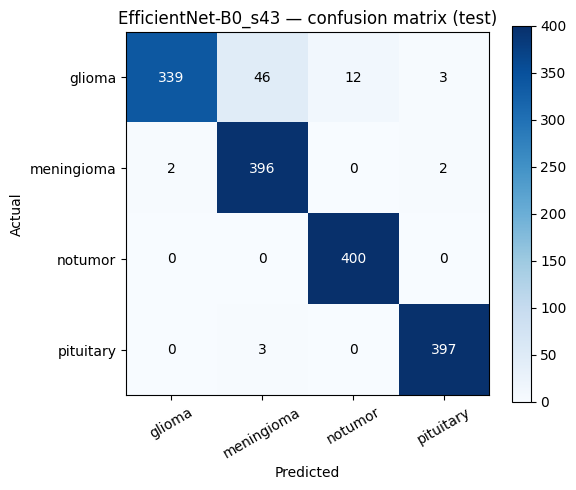

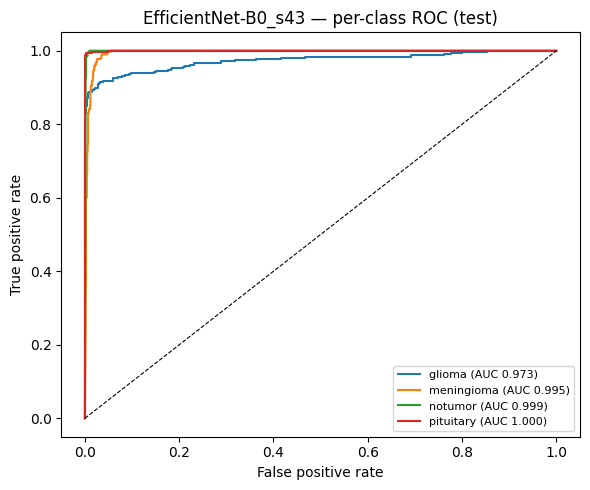

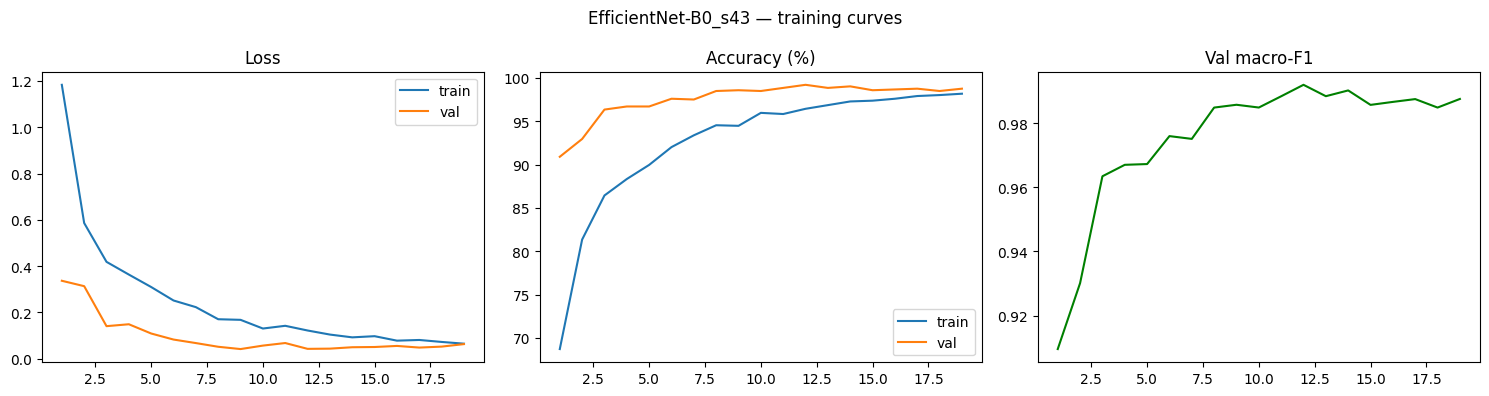

              precision    recall  f1-score   support

      glioma     0.9941    0.8475    0.9150       400
  meningioma     0.8899    0.9900    0.9373       400
     notumor     0.9709    1.0000    0.9852       400
   pituitary     0.9876    0.9925    0.9900       400

    accuracy                         0.9575      1600
   macro avg     0.9606    0.9575    0.9569      1600
weighted avg     0.9606    0.9575    0.9569      1600

DONE EfficientNet-B0_s43 | test accuracy 95.75% | macro-F1 0.9569 | best epoch 12
  [stage complete] train:EfficientNet-B0_s43

TRAINING EfficientNet-B0_s44 (efficientnet_b0) on cuda — resumable, run once
  Epoch 01/30 | train 1.2096/66.76% | val 0.3904/90.80% | valF1 0.9090 | lr 1.00e-04 | ETA 20 min
    * new best — weights saved (val macro-F1 0.9090)
  Epoch 02/30 | train 0.6224/79.69% | val 0.2523/91.79% | valF1 0.9183 | lr 9.97e-05 | ETA 19 min
    * new best — weights saved (val macro-F1 0.9183)
  Epoch 03/30 | train 0.4182/86.18% | val 0.1617/95.45% | 

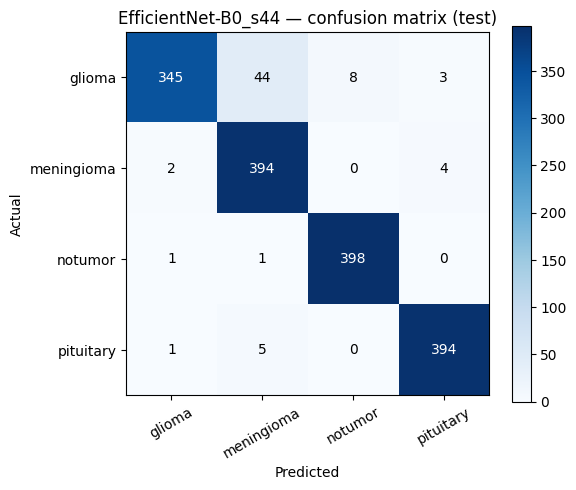

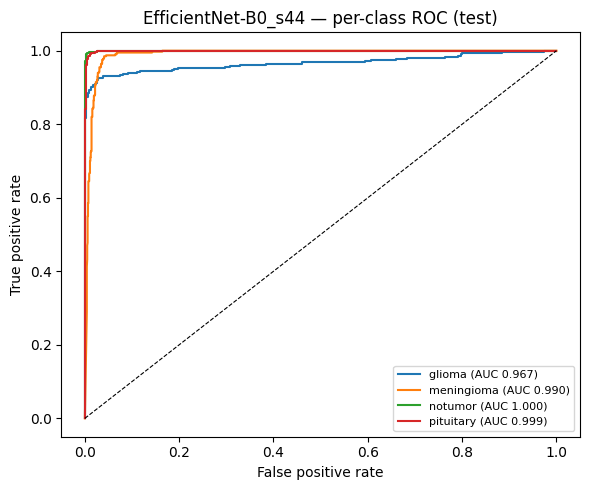

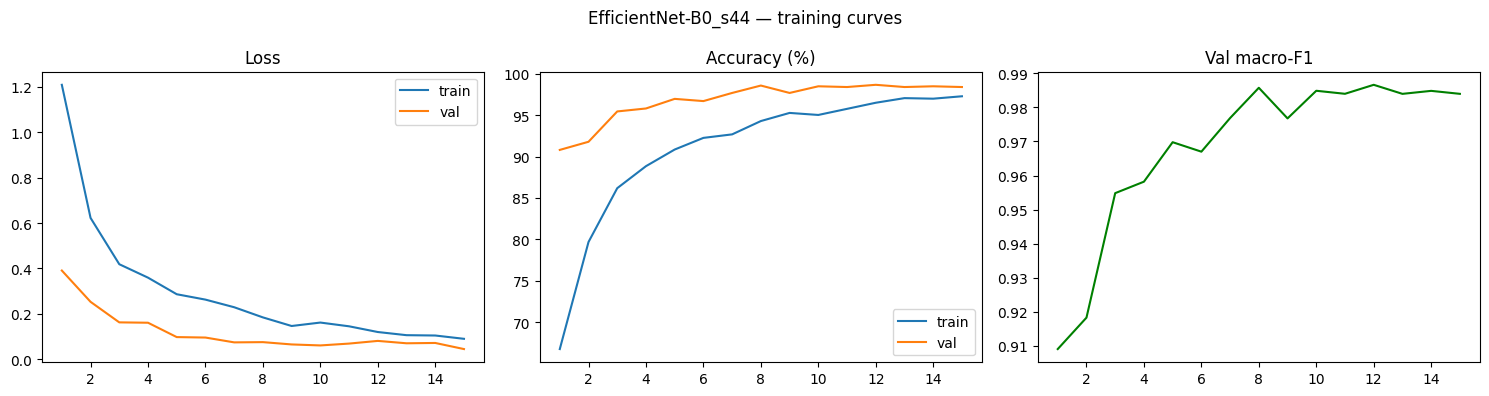

              precision    recall  f1-score   support

      glioma     0.9885    0.8625    0.9212       400
  meningioma     0.8874    0.9850    0.9336       400
     notumor     0.9803    0.9950    0.9876       400
   pituitary     0.9825    0.9850    0.9838       400

    accuracy                         0.9569      1600
   macro avg     0.9597    0.9569    0.9566      1600
weighted avg     0.9597    0.9569    0.9566      1600

DONE EfficientNet-B0_s44 | test accuracy 95.69% | macro-F1 0.9566 | best epoch 12
  [stage complete] train:EfficientNet-B0_s44


,run,seed,test acc (%),macro-F1
0,EfficientNet-B0,42,96.31,0.9626
1,EfficientNet-B0_s43,43,95.75,0.9569
2,EfficientNet-B0_s44,44,95.69,0.9566


  EfficientNet-B0 across 3 seeds: acc 95.92% ± 0.28 pp | macro-F1 0.9587 ± 0.0028
  [stage complete] seed_stability


In [22]:
# ============================================================================
# STAGE 12 · SEED STABILITY — the best model, three seeds.
# One number from one seed is a sample of one; the honest report is mean ±
# std. The best model is re-trained at seeds 43 and 44 into its own model
# directories (canonical seed-42 artifacts are never overwritten).
# ============================================================================
stage = "seed_stability"
if stage_done(stage):
    print("SKIP seed_stability — see results/seed_stability.json")
else:
    best_name = df.iloc[0]["Model"]
    spec, mtype = Config.MODELS[best_name]
    for seed in (43, 44):
        train_one_model(f"{best_name}_s{seed}", spec, mtype, seed=seed)

    rows = []
    for name in (best_name, f"{best_name}_s43", f"{best_name}_s44"):
        ev = json.loads((Config.MODELS_DIR / name / "eval.json").read_text(encoding="utf-8"))
        rows.append({"run": name, "seed": ev["seed"],
                     "test acc (%)": round(ev["accuracy"] * 100, 2),
                     "macro-F1": round(ev["f1_macro"], 4)})
    sdf = pd.DataFrame(rows)
    display(sdf)
    accs = np.array([r["test acc (%)"] for r in rows])
    f1s  = np.array([r["macro-F1"] for r in rows])
    atomic_write_json(Config.RESULTS_DIR / "seed_stability.json",
                      {"best_model": best_name, "runs": rows,
                       "acc_mean": float(accs.mean()), "acc_std_pp": float(accs.std()),
                       "f1_mean": float(f1s.mean()), "f1_std": float(f1s.std())})
    print(f"  {best_name} across 3 seeds: acc {accs.mean():.2f}% ± {accs.std():.2f} pp "
          f"| macro-F1 {f1s.mean():.4f} ± {f1s.std():.4f}")
    mark_stage(stage, {"best_model": best_name})


## Stage 13 — final summary

In [23]:
# ============================================================================
# STAGE 13 · FINAL SUMMARY — generates results/SUMMARY.md
# (Assembled ONLY from the JSON/CSV records earlier stages wrote — nothing is
# recomputed, so a duplicate or contradictory number is structurally
# impossible. The original's version of this cell crashed after 3 lines
# because three incompatible result schemas coexisted.)
# Environment-aware: test count and training device come from
# environment.json instead of hard-coded text.
# ============================================================================
summary = []
summary.append("# Brain Tumor MRI Classification — v2 Clean Rebuild — Results Summary")
summary.append("")
summary.append(f"Generated: {datetime.now().isoformat(timespec='seconds')}")
summary.append("")
env = json.loads((Config.RESULTS_DIR / "environment.json").read_text(encoding="utf-8"))
summary.append("## Environment")
summary.append(f"- Machine: {env.get('machine', '?')} | training device: {env.get('training_device')}")
summary.append(f"- torch {env.get('pkg_torch')} | timm {env.get('pkg_timm')} | "
               f"sklearn {env.get('pkg_sklearn')} | numpy {env.get('pkg_numpy')}")
summary.append(f"- Dataset: {env.get('dataset_provenance', '')}")
if (Config.RESULTS_DIR / "data_quality.json").exists():
    dq = json.loads((Config.RESULTS_DIR / "data_quality.json").read_text(encoding="utf-8"))
    summary.append("")
    summary.append("## Data-quality audit (leakage disclosure)")
    for k, v in dq.items():
        if k != "note":
            summary.append(f"- {k}: {v}")
    summary.append(f"- {dq.get('note', '')}")
summary.append("")
test_images = env.get("dataset_counts", {}).get("test", {})
test_count = sum(test_images.values()) if test_images else "?"
summary.append(f"## Model comparison (sealed test set, {test_count} images)")
summary.append("```")
summary.append(df.to_string(index=False))
summary.append("```")
REFERENCE = {"DeiT-Tiny": 99.31, "TinyViT-5M": 99.24, "EfficientNet-B0": 98.93,
             "MobileViT-S": 98.86, "MobileNetV3-Small": 98.78}
summary.append("")
summary.append("Reference run (Azure CPU session, Nov 2025): " +
               ", ".join(f"{k} {v}%" for k, v in REFERENCE.items()))
summary.append("Note: the reference run was scored on Version 1 of this dataset "
               "(2021 release — 5,712/1,311 images, 103 exact train/test copies, "
               "approximate fallback metrics); this run uses the 2026 Version 2 "
               "(5,600/1,600, exact overlap removed). The two scores are NOT "
               "directly comparable.")
if (Config.EXPORT_DIR / "onnx_parity.json").exists():
    par = json.loads((Config.EXPORT_DIR / "onnx_parity.json").read_text(encoding="utf-8"))
    summary.append("")
    summary.append("## ONNX export parity (max |Δlogit| vs PyTorch, 8-image fixed batch)")
    for k, v in par.items():
        summary.append(f"- {k}: {v['max_abs_diff']:.2e} "
                       f"({'PASS' if v['parity_ok'] else 'FAIL'})")
if (Config.RESULTS_DIR / "benchmarks.csv").exists():
    b = pd.read_csv(Config.RESULTS_DIR / "benchmarks.csv")
    summary.append("")
    summary.append("## Inference speed (median; warmup 10; 100 iters @ batch 1, 30 @ batch 16)")
    summary.append("```")
    summary.append(b.to_string(index=False))
    summary.append("```")
if (Config.RESULTS_DIR / "clean_subset_report.json").exists():
    cs = json.loads((Config.RESULTS_DIR / "clean_subset_report.json").read_text(encoding="utf-8"))
    summary.append("")
    summary.append("## Honest-split evaluation — clean test subset")
    summary.append(f"Of the {test_count} test images, {cs['dirty_test_images']} share a "
                   f"perceptual hash (Hamming<=8) with a training image and were removed; "
                   f"the remaining {cs['clean_test_images']} behave like unseen patients. "
                   "The full-vs-clean gap is the leakage premium of this benchmark:")
    summary.append("```")
    for r in cs["rows"]:
        summary.append(f"{r['Model']}: full {r['Full test acc (%)']}% -> clean "
                       f"{r['Clean subset acc (%)']}% (drop {r['Drop (pp)']} pp)")
    summary.append("```")
if (Config.RESULTS_DIR / "seed_stability.json").exists():
    ss = json.loads((Config.RESULTS_DIR / "seed_stability.json").read_text(encoding="utf-8"))
    summary.append("")
    summary.append("## Seed stability")
    summary.append(f"- Best model ({ss['best_model']}), 3 seeds: test accuracy "
                   f"{ss['acc_mean']:.2f}% ± {ss['acc_std_pp']:.2f} pp | "
                   f"macro-F1 {ss['f1_mean']:.4f} ± {ss['f1_std']:.4f}")
summary.append("")
summary.append("## Notes")
summary.append(f"- Training device: {env.get('training_device', '?')} ({env.get('device_name', '?')}).")
summary.append("- Test metrics are per-image on a dataset containing duplicated and "
               "patient-correlated slices (see data-quality audit); the clean-subset "
               "section above is the honest estimate. Disclosed rather than hidden.")
summary.append("- Research prototype only — not for clinical use. Single public dataset; "
               "no external or multi-institution validation.")

text = "\n".join(summary)
(Config.RESULTS_DIR / "SUMMARY.md").write_text(text, encoding="utf-8")
mark_stage("summary")
print(text)

  [stage complete] summary
# Brain Tumor MRI Classification — v2 Clean Rebuild — Results Summary

Generated: 2026-09-29T19:33:49

## Environment
- Machine: Linux-6.12.90+-x86_64-with-glibc2.35 | training device: cuda
- torch 2.10.0+cu128 | timm 1.0.26 | sklearn 1.6.1 | numpy 2.0.2
- Dataset: Kaggle 'Brain Tumor MRI Dataset' by Masoud Nickparvar (masoudnickparvar/brain-tumor-mri-dataset). Public Kaggle version: 5,600 Training / 1,600 Testing (balanced 1,400/class train, 400/class test). Local v2 copy: 5,712 Training / 1,311 Testing (unbalanced). Combines Figshare (Cheng Jun) + SARTAJ + Br35H. The original notebook's download cell cited sartajbhuvaji/brain-tumor-classification-mri, which is a DIFFERENT dataset (2,870/3,919) - citation corrected in v2.

## Data-quality audit (leakage disclosure)
- exact_duplicates_within_train: 171
- exact_duplicates_within_test: 16
- exact_duplicates_train_test_overlap: 0
- near_duplicates_test_with_near_match_in_train (pHash Hamming<=8): 1248
- near_dup

---
**Finished.** Everything lives in `results/` — `SUMMARY.md` (human report), `model_comparison.csv`, `benchmarks.csv`, `clean_subset_report.json`, `seed_stability.json`, per-model `eval.json` + plots, and the manifest that makes the whole notebook re-runnable without recomputing anything. See `README.md` for repo-packaging guidance (what belongs in git, what belongs in a Release).